# 📘 **Actividad 5. Preparación de datos, entrenamiento y seguimiento de modelos**

**Materia:** Gestión de Proyectos de Inteligencia Artificial  
**Módulo:** 2  
**Semana:** 6  
**Actividad:** 5. Design thinking, definiendo e ideando

**Proyecto:** Asistente inteligente para comprensión, orientación y cotización de seguros de vida mediante inteligencia artificial generativa.

---

## 🎯 **Objetivo de la actividad**

Realizar la preparación de los datos, el entrenamiento de modelos de aprendizaje automático y el registro de los resultados obtenidos.

Para ello, se utilizará un dataset público relacionado con consultas de seguros y se implementará un proceso reproducible de limpieza, transformación, entrenamiento, evaluación y comparación de modelos.

Los experimentos serán registrados mediante MLflow, con el propósito de garantizar la trazabilidad y facilitar la comparación de resultados.

---

# 📝 **INICIO DE LA INSTRUCCIÓN 1**
## 💻 **1. Preparación del entorno y repositorio**

### 🧠 **1.a. Creación y organización del repositorio en GitHub**

Para el desarrollo de esta actividad se utilizará el repositorio público del proyecto académico:

**Repositorio:**  
https://github.com/mauroene/asistente-seguros-ia

Se creó la carpeta `Actividad5`, conservando los archivos y resultados correspondientes a las actividades anteriores.

La estructura inicial del proyecto comprende:

- `datos/datos_ini/`: almacenamiento de datos originales.
- `datos/datos_limp/`: almacenamiento de datos procesados.
- `fuentes/entrena.ipynb`: notebook principal de entrenamiento y evaluación.
- `fuentes/datos_prep.py`: funciones de preparación de datos.
- `fuentes/train.py`: entrenamiento, evaluación y registro de experimentos.
- `README.md`: documentación del proyecto y guía de reproducibilidad.
- `CHANGELOG.md`: registro de modificaciones y versionamiento.

Esta organización permite separar los datos originales de los procesados, facilitar la reutilización del código y mantener un historial de cambios.

### 🧠 **1.b. Inicialización de Git y conexión con GitHub**

Se reutilizó el repositorio existente, previamente inicializado y conectado con GitHub.

Los archivos de la Actividad 5 se incorporaron mediante commits en la rama principal (`main`), conservando el historial de versiones del proyecto.

La creación de la estructura inicial y de los archivos de documentación quedó registrada en GitHub.

### 🔘 **Estado de la instrucción**

La estructura inicial del repositorio se encuentra preparada.

La incorporación del notebook, los scripts y las dependencias necesarias se realizará durante el desarrollo de la actividad.

El cierre de la Instrucción 1 se documentará una vez completada y verificada la integración de estos elementos.

### 🧠 **1.c. Preparación del entorno de ejecución en Google Colab**

Para garantizar la reproducibilidad de los experimentos,
se utilizará Google Colab como entorno de desarrollo
y Python como lenguaje de programación.

Se instalarán y verificarán las bibliotecas necesarias
para las siguientes actividades:

- **datasets:** descarga y manejo del dataset público.
- **pandas y numpy:** manipulación y análisis de datos.
- **scikit-learn:** preparación, entrenamiento y evaluación
  de los modelos de clasificación.
- **matplotlib y seaborn:** visualización de datos y resultados.
- **MLflow:** seguimiento y registro de experimentos.

La configuración del entorno permitirá desarrollar
los procesos de preparación de datos, entrenamiento,
validación cruzada y comparación de modelos.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - PREPARACIÓN DEL ENTORNO
# Instalación de bibliotecas necesarias
# ============================================================

%pip install -q datasets mlflow scikit-learn pandas numpy matplotlib seaborn

# Confirmación de finalización del proceso
print("=" * 65)
print("✅ Instalación de dependencias completada.")
print("=" * 65)

✅ Instalación de dependencias completada.


In [ ]:
# ============================================================
# ACTIVIDAD 5 - INSTRUCCIÓN 1
# Verificación de bibliotecas y versiones del entorno
# ============================================================

print("=" * 65)
print("🔍 Verificando bibliotecas del entorno de ejecución")
print("=" * 65)

# Importar las bibliotecas necesarias
import sys
import pandas as pd
import numpy as np
import sklearn
import datasets
import mlflow
import matplotlib
import seaborn as sns

# Mostrar las versiones instaladas
print(f"\nPython: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"Datasets: {datasets.__version__}")
print(f"MLflow: {mlflow.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Seaborn: {sns.__version__}")

# Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Verificación de bibliotecas completada correctamente.")
print("=" * 65)

🔍 Verificando bibliotecas del entorno de ejecución

Python: 3.13.16
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
Datasets: 4.8.5
MLflow: 3.17.0
Matplotlib: 3.10.0
Seaborn: 0.13.2

✅ Verificación de bibliotecas completada correctamente.


### 🧠 **1.d. Obtención y verificación del dataset público**

Para el entrenamiento y evaluación de los modelos se utilizará
el dataset público **Bitext Insurance LLM Chatbot Training Dataset**,
disponible en Hugging Face.

**Identificador del dataset:**
`bitext/Bitext-insurance-llm-chatbot-training-dataset`

Este conjunto de datos fue utilizado previamente en la
Actividad 4, lo que permite mantener la continuidad del
proyecto académico.

El dataset contiene aproximadamente 39,000 registros
relacionados con consultas de usuarios sobre seguros.

Las variables principales son:

- `instruction`: consulta formulada por el usuario.
- `intent`: intención asociada con la consulta.
- `category`: categoría temática de la consulta.
- `tags`: etiquetas complementarias.
- `response`: respuesta asociada con la consulta.

**Variable de entrada:** `instruction`.

**Variable objetivo:** `category`.

El problema se abordará mediante clasificación supervisada
multiclase.

Inicialmente se verificará la estructura, el número de
registros, los tipos de datos y la distribución de categorías.

La limpieza y transformación se realizarán posteriormente,
conservando una copia de los datos originales.

**Nota metodológica:** La descarga y exploración inicial
se documentan aquí como parte de la preparación del entorno.
El análisis detallado de calidad y limpieza se desarrollará
en la sección correspondiente del notebook.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - INSTRUCCIÓN 1
# Obtención y verificación inicial del dataset
# ============================================================

from datasets import load_dataset
import pandas as pd

print("=" * 65)
print("📥 Cargando dataset público de seguros desde Hugging Face")
print("=" * 65)

# Identificador del dataset
dataset_id = "bitext/Bitext-insurance-llm-chatbot-training-dataset"

# Descargar el dataset
dataset = load_dataset(dataset_id)

# Mostrar las particiones disponibles
print("\nParticiones disponibles:")
print(dataset)

# Convertir la partición de entrenamiento a DataFrame
df_original = dataset["train"].to_pandas()

# Mostrar dimensiones
print("\nDimensiones del dataset:")
print(f"Registros: {df_original.shape[0]:,}")
print(f"Columnas: {df_original.shape[1]}")

# Mostrar nombres de las columnas
print("\nColumnas disponibles:")
print(df_original.columns.tolist())

# Mostrar los primeros cinco registros
print("\nPrimeros cinco registros:")
display(df_original.head())

# Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Dataset cargado y verificado correctamente.")
print("=" * 65)

📥 Cargando dataset público de seguros desde Hugging Face


README.md:   0%|          | 0.00/9.52k [00:00<?, ?B/s]

bitext-insurance-llm-chatbot-training-da(…): reconstructing file:   0%|          |  0.00B / 27.2MB            

bitext-insurance-llm-chatbot-training-da(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/39000 [00:00<?, ? examples/s]


Particiones disponibles:
DatasetDict({
    train: Dataset({
        features: ['instruction', 'intent', 'category', 'tags', 'response'],
        num_rows: 39000
    })
})

Dimensiones del dataset:
Registros: 39,000
Columnas: 5

Columnas disponibles:
['instruction', 'intent', 'category', 'tags', 'response']

Primeros cinco registros:


,instruction,intent,category,tags,response
0,"I'd like to see my fucking auto insurance , I ...",information_auto_insurance,AUTO_INSURANCE,BCLPWZ,To retrieve the details of your auto insurance...
1,wanna know more about my auto insurance giev m...,information_auto_insurance,AUTO_INSURANCE,BCQZ,"To retrieve your auto insurance details, pleas..."
2,I'd like to sde my fucking auto insurance coul...,information_auto_insurance,AUTO_INSURANCE,BCILPQWZ,"To obtain your auto insurance information, kin..."
3,wanna see my fucking auto insurance where coul...,information_auto_insurance,AUTO_INSURANCE,BCILPQW,"To retrieve your auto insurance details, pleas..."
4,I need information about my fucking auto insur...,information_auto_insurance,AUTO_INSURANCE,BCIW,"To retrieve your auto insurance details, pleas..."



✅ Dataset cargado y verificado correctamente.


### 🧠 **1.e. Diagnóstico inicial de calidad de los datos**

Una vez cargado el dataset, se realizará un diagnóstico
preliminar para identificar posibles problemas de calidad
antes de aplicar transformaciones.

El análisis comprende:

1. Verificación de tipos de datos.
2. Identificación de valores nulos.
3. Detección de registros duplicados.
4. Revisión de categorías disponibles.
5. Identificación de posibles inconsistencias.

Los resultados permitirán establecer criterios de limpieza
y documentar las transformaciones realizadas.

En esta etapa no se modificará el dataset original,
con el propósito de conservar su integridad y facilitar
la trazabilidad de los cambios.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - DIAGNÓSTICO DE CALIDAD
# Análisis inicial del dataset original
# ============================================================

print("=" * 65)
print("🔍 INICIO DEL DIAGNÓSTICO DE CALIDAD DE DATOS")
print("=" * 65)

# 1. Verificar dimensiones
print("\n1. DIMENSIONES DEL DATASET")
print(f"Registros: {df_original.shape[0]:,}")
print(f"Columnas: {df_original.shape[1]}")

# 2. Identificar tipos de datos
print("\n2. TIPOS DE DATOS")
print(df_original.dtypes)

# 3. Identificar valores nulos
print("\n3. VALORES NULOS POR COLUMNA")

nulos = df_original.isnull().sum()

display(
    pd.DataFrame({
        "Columna": nulos.index,
        "Valores nulos": nulos.values,
        "Porcentaje (%)": (
            nulos.values / len(df_original) * 100
        ).round(2)
    })
)

# 4. Identificar registros duplicados
print("\n4. REGISTROS DUPLICADOS")

duplicados_completos = df_original.duplicated().sum()

duplicados_consultas = df_original.duplicated(
    subset=["instruction"]
).sum()

print(f"Duplicados completos: {duplicados_completos:,}")
print(f"Consultas repetidas: {duplicados_consultas:,}")

# 5. Revisar categorías
print("\n5. DISTRIBUCIÓN DE CATEGORÍAS")

distribucion = (
    df_original["category"]
    .value_counts()
    .reset_index()
)

distribucion.columns = ["Categoría", "Registros"]

display(distribucion)

# 6. Verificar cantidad de categorías
print("\n6. TOTAL DE CATEGORÍAS")

total_categorias = df_original["category"].nunique()

print(f"Categorías identificadas: {total_categorias}")

# Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Diagnóstico inicial de calidad completado correctamente.")
print("=" * 65)

🔍 INICIO DEL DIAGNÓSTICO DE CALIDAD DE DATOS

1. DIMENSIONES DEL DATASET
Registros: 39,000
Columnas: 5

2. TIPOS DE DATOS
instruction    object
intent         object
category       object
tags           object
response       object
dtype: object

3. VALORES NULOS POR COLUMNA


,Columna,Valores nulos,Porcentaje (%)
0,instruction,0,0.0
1,intent,0,0.0
2,category,0,0.0
3,tags,0,0.0
4,response,0,0.0



4. REGISTROS DUPLICADOS
Duplicados completos: 0
Consultas repetidas: 17

5. DISTRIBUCIÓN DE CATEGORÍAS


,Categoría,Registros
0,CLAIMS,6000
1,PAYMENT,5000
2,ENROLLMENT,4000
3,COVERAGE,4000
4,CONTACT,4000
5,COMPLAINTS,3000
6,INCIDENTS,2000
7,QUOTE,2000
8,AUTO_INSURANCE,1000
9,HOME_INSURANCE,1000



6. TOTAL DE CATEGORÍAS
Categorías identificadas: 17

✅ Diagnóstico inicial de calidad completado correctamente.


### 🧠 **1.f. Análisis de consultas repetidas e inconsistencias**

El diagnóstico inicial identificó 17 registros con valores
repetidos en la variable `instruction`, aunque no se
encontraron registros completamente duplicados.

Se realizará una revisión específica para determinar
si las consultas repetidas presentan categorías
coincidentes o diferentes.

Este análisis permitirá establecer criterios de limpieza
fundamentados y evitar la eliminación injustificada
de información.

Asimismo, se verificará la presencia de cadenas vacías
y espacios innecesarios en las variables principales.

Los datos originales permanecerán sin modificaciones.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - ANÁLISIS DE CALIDAD
# Revisión de consultas repetidas e inconsistencias
# ============================================================

print("=" * 65)
print("🔍 Analizando consultas repetidas e inconsistencias")
print("=" * 65)

# 1. Identificar todos los registros con consultas repetidas
consultas_repetidas = df_original[
    df_original.duplicated(
        subset=["instruction"],
        keep=False
    )
].copy()

# Ordenar para facilitar su revisión
consultas_repetidas = consultas_repetidas.sort_values(
    by="instruction"
)

print("\n1. REGISTROS CON CONSULTAS REPETIDAS")
print(f"Registros involucrados: {len(consultas_repetidas)}")

# 2. Identificar consultas únicas repetidas
total_consultas = consultas_repetidas["instruction"].nunique()

print(f"Consultas distintas repetidas: {total_consultas}")

# 3. Identificar consultas con categorías diferentes
categorias_por_consulta = (
    consultas_repetidas
    .groupby("instruction")["category"]
    .nunique()
)

consultas_conflictivas = categorias_por_consulta[
    categorias_por_consulta > 1
]

print("\n2. POSIBLES CONFLICTOS DE CLASIFICACIÓN")
print(
    "Consultas asociadas con categorías diferentes:",
    len(consultas_conflictivas)
)

# 4. Mostrar ejemplos para revisión
print("\n3. EJEMPLOS DE CONSULTAS REPETIDAS")

display(
    consultas_repetidas[
        ["instruction", "intent", "category"]
    ].head(20)
)

# 5. Verificar cadenas vacías o espacios
print("\n4. VERIFICACIÓN DE CADENAS VACÍAS")

columnas_texto = [
    "instruction",
    "intent",
    "category",
    "tags",
    "response"
]

for columna in columnas_texto:

    vacios = (
        df_original[columna]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"{columna}: {vacios} valores vacíos")

# Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Análisis de consultas repetidas completado correctamente.")
print("=" * 65)

🔍 Analizando consultas repetidas e inconsistencias

1. REGISTROS CON CONSULTAS REPETIDAS
Registros involucrados: 34
Consultas distintas repetidas: 17

2. POSIBLES CONFLICTOS DE CLASIFICACIÓN
Consultas asociadas con categorías diferentes: 0

3. EJEMPLOS DE CONSULTAS REPETIDAS


,instruction,intent,category
27722,I'd like to check my life insurance,information_life_insurance,LIFE_INSURANCE
27697,I'd like to check my life insurance,information_life_insurance,LIFE_INSURANCE
38863,I'd like to check my travel insurance,information_travel_insurance,TRAVEL_INSURANCE
38623,I'd like to check my travel insurance,information_travel_insurance,TRAVEL_INSURANCE
8756,I'd like to dispute an invoice,dispute_invoice,COMPLAINTS
8431,I'd like to dispute an invoice,dispute_invoice,COMPLAINTS
2167,I'd like to file a fucking travel insurance claim,file_claim,CLAIMS
2552,I'd like to file a fucking travel insurance claim,file_claim,CLAIMS
371,I'd like to know about my fucking auto insurance,information_auto_insurance,AUTO_INSURANCE
839,I'd like to know about my fucking auto insurance,information_auto_insurance,AUTO_INSURANCE



4. VERIFICACIÓN DE CADENAS VACÍAS
instruction: 0 valores vacíos
intent: 0 valores vacíos
category: 0 valores vacíos
tags: 0 valores vacíos
response: 0 valores vacíos

✅ Análisis de consultas repetidas completado correctamente.


### 🧠 **1.g. Limpieza y estandarización inicial del dataset**

A partir del diagnóstico de calidad se identificaron
17 consultas repetidas, correspondientes a 34 registros.

No se encontraron valores nulos, cadenas vacías ni
consultas repetidas asociadas con categorías diferentes.

Con base en estos resultados se establecieron las
siguientes reglas de preparación:

1. Conservar una copia íntegra del dataset original.
2. Eliminar espacios innecesarios en las variables textuales.
3. Eliminar consultas duplicadas conservando su primera aparición.
4. Mantener las categorías originales.
5. Conservar las expresiones informales presentes en las consultas.
6. Verificar la integridad de los datos procesados.

La eliminación de consultas repetidas busca evitar
la sobreestimación del desempeño de los modelos
y reducir la posibilidad de contaminación entre
los conjuntos de entrenamiento y prueba.

La transformación numérica de los textos se realizará
posteriormente mediante TF-IDF, utilizando un pipeline
de aprendizaje automático para prevenir fugas de información.

Los resultados de esta limpieza se documentarán
para garantizar la trazabilidad del proceso.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - PREPARACIÓN DE DATOS
# Limpieza y estandarización inicial del dataset
# ============================================================

print("=" * 65)
print("🧹 INICIANDO LIMPIEZA Y ESTANDARIZACIÓN DEL DATASET")
print("=" * 65)

# 1. Crear una copia para conservar los datos originales
df_limpio = df_original.copy()

registros_iniciales = len(df_limpio)

print(f"\nRegistros originales: {registros_iniciales:,}")

# 2. Eliminar espacios al inicio y final de los textos
columnas_texto = [
    "instruction",
    "intent",
    "category",
    "tags",
    "response"
]

for columna in columnas_texto:
    df_limpio[columna] = (
        df_limpio[columna]
        .astype(str)
        .str.strip()
    )

print("\n✅ Estandarización de espacios completada.")

# 3. Verificar conflictos después de estandarizar
conflictos = (
    df_limpio.groupby("instruction")["category"]
    .nunique()
)

total_conflictos = (conflictos > 1).sum()

print(f"\nConsultas con categorías conflictivas: {total_conflictos}")

# Evitar eliminar registros si existen conflictos
if total_conflictos > 0:
    raise ValueError(
        "Se detectaron consultas con categorías diferentes. "
        "Es necesario revisarlas antes de continuar."
    )

# 4. Eliminar consultas repetidas
df_limpio = df_limpio.drop_duplicates(
    subset=["instruction"],
    keep="first"
).reset_index(drop=True)

# 5. Calcular resultados
registros_finales = len(df_limpio)

registros_eliminados = (
    registros_iniciales - registros_finales
)

porcentaje_eliminado = (
    registros_eliminados / registros_iniciales
) * 100

# 6. Mostrar resumen
print("\n" + "=" * 65)
print("📊 RESULTADOS DE LA LIMPIEZA")
print("=" * 65)

print(f"Registros iniciales: {registros_iniciales:,}")
print(f"Registros finales: {registros_finales:,}")
print(f"Registros eliminados: {registros_eliminados:,}")
print(f"Porcentaje eliminado: {porcentaje_eliminado:.4f}%")

# 7. Verificaciones finales
assert df_limpio["instruction"].duplicated().sum() == 0
assert df_limpio[columnas_texto].isnull().sum().sum() == 0
assert df_limpio[columnas_texto].apply(
    lambda columna: columna.eq("").sum()
).sum() == 0

print("\n✅ Verificaciones de integridad superadas.")

# 8. Mostrar una muestra del dataset limpio
print("\nPrimeros cinco registros del dataset limpio:")
display(df_limpio.head())

# Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Limpieza y estandarización completadas correctamente.")
print("=" * 65)

🧹 INICIANDO LIMPIEZA Y ESTANDARIZACIÓN DEL DATASET

Registros originales: 39,000

✅ Estandarización de espacios completada.

Consultas con categorías conflictivas: 0

📊 RESULTADOS DE LA LIMPIEZA
Registros iniciales: 39,000
Registros finales: 38,983
Registros eliminados: 17
Porcentaje eliminado: 0.0436%

✅ Verificaciones de integridad superadas.

Primeros cinco registros del dataset limpio:


,instruction,intent,category,tags,response
0,"I'd like to see my fucking auto insurance , I ...",information_auto_insurance,AUTO_INSURANCE,BCLPWZ,To retrieve the details of your auto insurance...
1,wanna know more about my auto insurance giev m...,information_auto_insurance,AUTO_INSURANCE,BCQZ,"To retrieve your auto insurance details, pleas..."
2,I'd like to sde my fucking auto insurance coul...,information_auto_insurance,AUTO_INSURANCE,BCILPQWZ,"To obtain your auto insurance information, kin..."
3,wanna see my fucking auto insurance where coul...,information_auto_insurance,AUTO_INSURANCE,BCILPQW,"To retrieve your auto insurance details, pleas..."
4,I need information about my fucking auto insur...,information_auto_insurance,AUTO_INSURANCE,BCIW,"To retrieve your auto insurance details, pleas..."



✅ Limpieza y estandarización completadas correctamente.


### 🔘 **Interpretación de los resultados de limpieza**

El proceso de preparación permitió reducir el conjunto de
datos de 39,000 a 38,983 registros, mediante la eliminación
de 17 consultas repetidas.

Los registros eliminados representan únicamente el 0.0436%
del conjunto original, por lo que se conservó aproximadamente
el 99.96% de la información disponible.

No se identificaron conflictos entre las categorías asociadas
con las consultas repetidas.

Asimismo, las verificaciones posteriores confirmaron la
ausencia de valores nulos, cadenas vacías y consultas
duplicadas en la variable `instruction`.

La limpieza se realizó conservando intacto el DataFrame
original y generando una versión procesada denominada
`df_limpio`.

Esta estrategia permite mantener la trazabilidad de las
transformaciones y facilita la reproducción del procedimiento.

**Decisión técnica:** utilizar los 38,983 registros limpios
como base para la preparación de los conjuntos de
entrenamiento y evaluación.

La vectorización TF-IDF se realizará posteriormente
dentro de los pipelines de entrenamiento, evitando
ajustar el vectorizador con información del conjunto
de prueba.

### 🧠 **1.h. Análisis visual de la distribución de categorías**

Se analizará gráficamente la distribución de registros
por categoría después del proceso de limpieza.

El objetivo es identificar diferencias en la representación
de las clases y determinar sus posibles implicaciones
para el entrenamiento y evaluación de los modelos.

Se utilizará una gráfica de barras horizontales para
facilitar la comparación de las 17 categorías.

Los resultados permitirán justificar la selección de
métricas de evaluación multiclase, particularmente
precision, recall y F1-score macro.

También se revisará la representación de la categoría
`LIFE_INSURANCE`, debido a su relación directa con
el proyecto académico.

📊 INICIANDO ANÁLISIS VISUAL DE CATEGORÍAS


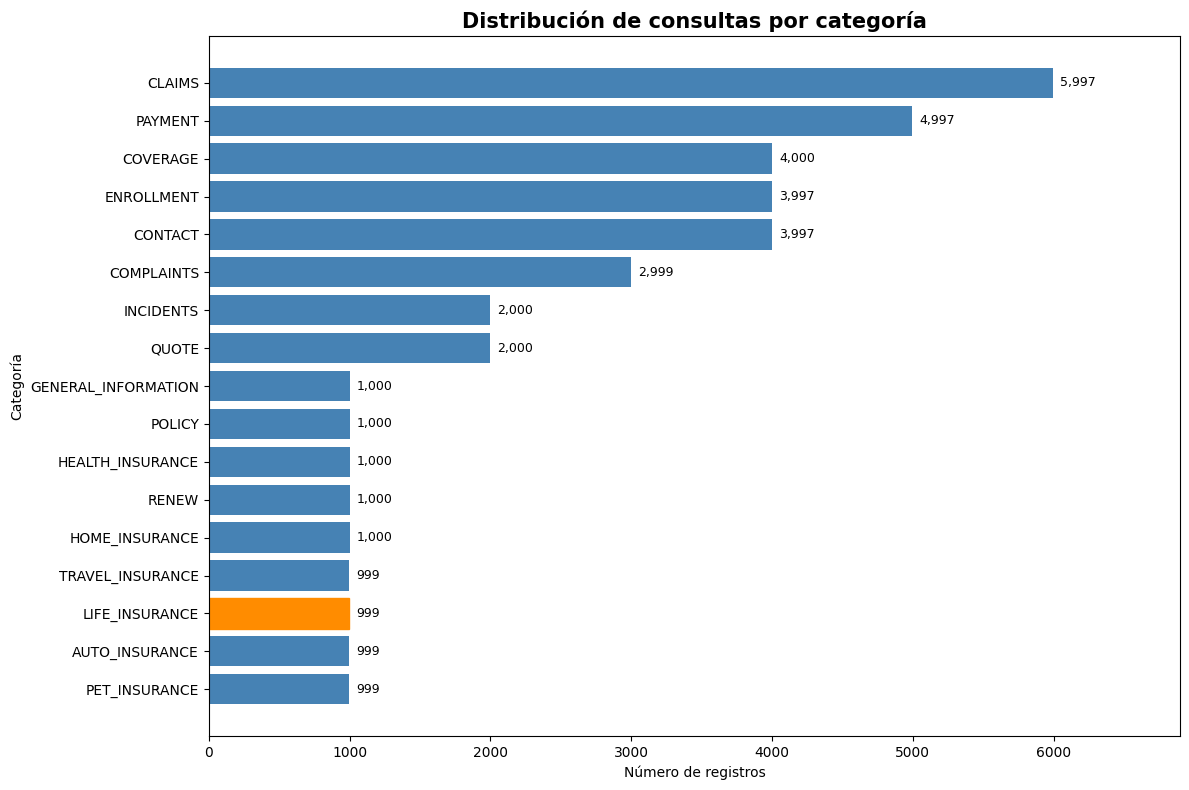


RESUMEN DE DISTRIBUCIÓN
Categorías: 17
Categoría más frecuente: CLAIMS (5,997 registros)
Categoría menos frecuente: PET_INSURANCE (999 registros)

CATEGORÍA LIFE_INSURANCE
Registros: 999
Participación: 2.56%

✅ Análisis visual de categorías completado correctamente.


In [ ]:
# ============================================================
# ACTIVIDAD 5 - ANÁLISIS EXPLORATORIO
# Visualización de la distribución de categorías
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

print("=" * 65)
print("📊 INICIANDO ANÁLISIS VISUAL DE CATEGORÍAS")
print("=" * 65)

# 1. Calcular distribución de categorías
conteo_categorias = (
    df_limpio["category"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Crear gráfica
fig, ax = plt.subplots(figsize=(12, 8))

barras = ax.barh(
    conteo_categorias.index,
    conteo_categorias.values,
    color="steelblue"
)

# Destacar la categoría relacionada con seguros de vida
for barra, categoria in zip(
    barras,
    conteo_categorias.index
):
    if categoria == "LIFE_INSURANCE":
        barra.set_color("darkorange")

# 3. Incorporar valores en las barras
for barra in barras:
    ancho = barra.get_width()

    ax.text(
        ancho + 50,
        barra.get_y() + barra.get_height() / 2,
        f"{int(ancho):,}",
        va="center",
        fontsize=9
    )

# 4. Configurar títulos y etiquetas
ax.set_title(
    "Distribución de consultas por categoría",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Número de registros")
ax.set_ylabel("Categoría")

ax.set_xlim(0, conteo_categorias.max() * 1.15)

plt.tight_layout()
plt.show()

# 5. Mostrar estadísticas relevantes
print("\nRESUMEN DE DISTRIBUCIÓN")

print(f"Categorías: {len(conteo_categorias)}")

print(
    f"Categoría más frecuente: "
    f"{conteo_categorias.idxmax()} "
    f"({conteo_categorias.max():,} registros)"
)

print(
    f"Categoría menos frecuente: "
    f"{conteo_categorias.idxmin()} "
    f"({conteo_categorias.min():,} registros)"
)

# 6. Revisar seguros de vida
registros_vida = conteo_categorias["LIFE_INSURANCE"]

porcentaje_vida = (
    registros_vida / len(df_limpio)
) * 100

print("\nCATEGORÍA LIFE_INSURANCE")

print(f"Registros: {registros_vida:,}")
print(f"Participación: {porcentaje_vida:.2f}%")

# Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Análisis visual de categorías completado correctamente.")
print("=" * 65)

### 🔘 **Interpretación de la Figura 1**

**Figura 1. Distribución de consultas por categoría después de la limpieza del dataset.**

La visualización presenta la distribución de 38,983 registros
entre 17 categorías relacionadas con servicios de seguros.

Se observa un desequilibrio en la representación de las clases.
La categoría `CLAIMS` concentra 5,997 registros, mientras que
las categorías menos frecuentes contienen 999 registros.

La categoría `LIFE_INSURANCE`, directamente relacionada con
el proyecto académico, contiene 999 consultas, equivalentes
al 2.56% del conjunto procesado.

La diferencia entre las categorías más y menos frecuentes
representa aproximadamente una relación de 6 a 1.

Este comportamiento podría influir en el entrenamiento
de los modelos, favoreciendo las categorías con mayor
cantidad de ejemplos.

Por esta razón, se utilizará una partición estratificada
y se evaluarán los modelos mediante accuracy, precision,
recall y F1-score.

Se dará especial importancia al F1-score macro, debido
a que permite evaluar el desempeño promedio de las
17 categorías sin favorecer a las clases mayoritarias.

**Conclusión técnica:** el dataset es adecuado para
continuar con el entrenamiento de modelos de clasificación
multiclase, siempre que se considere el desequilibrio
observado durante la evaluación.

### 🧠 **1.i. Almacenamiento y versionamiento de los datos**

Para garantizar la conservación de los datos utilizados
durante los experimentos, se almacenarán dos versiones:

- **Versión original:** dataset descargado de Hugging Face,
  sin modificaciones.
- **Versión limpia:** dataset después de la estandarización
  de espacios y eliminación de consultas repetidas.

Los archivos se almacenarán inicialmente en Google Drive
para evitar su pérdida durante las desconexiones de Colab.

Posteriormente se integrarán al repositorio GitHub
o se documentará un procedimiento reproducible de obtención.

Esta estrategia permitirá conservar la trazabilidad
de las transformaciones y facilitar la reproducción
de los experimentos.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - VERSIONAMIENTO DE DATOS
# Almacenamiento en Google Drive / Master IA / Módulo 2
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd

print("=" * 65)
print("💾 INICIANDO ALMACENAMIENTO DE DATASETS")
print("=" * 65)

# 1. Conectar Google Drive
drive.mount("/content/drive")

# 2. Localizar la carpeta principal de la maestría
ruta_master = Path("/content/drive/MyDrive/Master IA")

assert ruta_master.exists(), (
    "No se encontró la carpeta Master IA."
)

# 3. Definir la ruta exacta de la materia
ruta_materia = (
    ruta_master
    / "5-Gestión de Proyectos de Inteligencia Artificial"
)

# Verificar que existe
assert ruta_materia.exists(), (
    "No se encontró la carpeta de Gestión de Proyectos."
)

print("✅ Carpeta de la materia localizada correctamente.")


# 4. Definir ubicación de la Actividad 5
ruta_base = (
    ruta_materia
    / "Modulo 2"
    / "Actividad 5"
)

# Comprobar que existe la carpeta del módulo
assert (ruta_materia / "Modulo 2").exists(), (
    "No se encontró la carpeta Modulo 2."
)

# 5. Crear carpetas de datos
ruta_original = ruta_base / "datos" / "datos_ini"
ruta_limpio = ruta_base / "datos" / "datos_limp"

ruta_original.mkdir(parents=True, exist_ok=True)
ruta_limpio.mkdir(parents=True, exist_ok=True)

# 6. Definir archivos
archivo_original = (
    ruta_original / "seguros_original_v1.csv"
)

archivo_limpio = (
    ruta_limpio / "seguros_limpio_v1.csv"
)

# 7. Guardar datasets
df_original.to_csv(
    archivo_original,
    index=False,
    encoding="utf-8"
)

df_limpio.to_csv(
    archivo_limpio,
    index=False,
    encoding="utf-8"
)

# 8. Verificar archivos
assert archivo_original.exists()
assert archivo_limpio.exists()

# 9. Mostrar resultados
print("\n📁 UBICACIÓN DEL PROYECTO")
print(ruta_base)

print("\n📊 ARCHIVOS GENERADOS")

print(f"\nOriginal: {archivo_original.name}")
print(f"Registros: {len(df_original):,}")
print(
    f"Tamaño: "
    f"{archivo_original.stat().st_size / 1024**2:.2f} MB"
)

print(f"\nLimpio: {archivo_limpio.name}")
print(f"Registros: {len(df_limpio):,}")
print(
    f"Tamaño: "
    f"{archivo_limpio.stat().st_size / 1024**2:.2f} MB"
)

# 10. Confirmación
print("\n" + "=" * 65)
print("✅ Datasets guardados y verificados correctamente.")
print("✅ Estructura de la Actividad 5 creada en Módulo 2.")
print("=" * 65)

💾 INICIANDO ALMACENAMIENTO DE DATASETS
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Carpeta de la materia localizada correctamente.

📁 UBICACIÓN DEL PROYECTO
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5

📊 ARCHIVOS GENERADOS

Original: seguros_original_v1.csv
Registros: 39,000
Tamaño: 25.98 MB

Limpio: seguros_limpio_v1.csv
Registros: 38,983
Tamaño: 25.97 MB

✅ Datasets guardados y verificados correctamente.
✅ Estructura de la Actividad 5 creada en Módulo 2.


### 🧠 **1.j. División estratificada de los datos**

Después de completar la limpieza y el almacenamiento
del dataset, se realizará la división de los datos
en conjuntos de entrenamiento y prueba.

Se utilizará una proporción de 80% para entrenamiento
y 20% para evaluación.

La división será estratificada para conservar
aproximadamente la distribución original de las
17 categorías.

**Variable predictora:** `instruction`.

**Variable objetivo:** `category`.

Se utilizará una semilla aleatoria fija (`random_state=42`)
para garantizar la reproducibilidad de los resultados.

Los conjuntos obtenidos permitirán entrenar y comparar
los algoritmos de regresión logística y Random Forest.

La transformación de texto mediante TF-IDF se ajustará
exclusivamente con los datos de entrenamiento, utilizando
pipelines de scikit-learn para evitar fugas de información.

El conjunto de prueba permanecerá separado durante
el entrenamiento, la validación cruzada y la selección
de hiperparámetros.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - PREPARACIÓN DE DATOS
# División estratificada: entrenamiento y prueba
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd

print("=" * 65)
print("📊 INICIANDO DIVISIÓN ESTRATIFICADA DEL DATASET")
print("=" * 65)

# 1. Definir variables predictora y objetivo
X = df_limpio["instruction"]
y = df_limpio["category"]

# 2. Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Mostrar dimensiones
print("\n1. DISTRIBUCIÓN DE REGISTROS")

print(f"Total de registros: {len(df_limpio):,}")
print(f"Entrenamiento: {len(X_train):,}")
print(f"Prueba: {len(X_test):,}")

# 4. Verificar categorías
print("\n2. VERIFICACIÓN DE CATEGORÍAS")

print(f"Categorías en entrenamiento: {y_train.nunique()}")
print(f"Categorías en prueba: {y_test.nunique()}")

# 5. Comparar distribuciones porcentuales
print("\n3. COMPARACIÓN DE DISTRIBUCIONES")

distribucion_comparativa = pd.DataFrame({
    "Dataset completo (%)":
        y.value_counts(normalize=True) * 100,

    "Entrenamiento (%)":
        y_train.value_counts(normalize=True) * 100,

    "Prueba (%)":
        y_test.value_counts(normalize=True) * 100
}).round(2)

display(distribucion_comparativa)

# 6. Verificar integridad de la división
assert len(X_train) + len(X_test) == len(df_limpio)

assert set(X_train.index).isdisjoint(set(X_test.index))

assert y_train.nunique() == y.nunique()
assert y_test.nunique() == y.nunique()

print("\n✅ Verificaciones de integridad superadas.")

# 7. Confirmación final
print("\n" + "=" * 65)
print("✅ División estratificada completada correctamente.")
print("=" * 65)

📊 INICIANDO DIVISIÓN ESTRATIFICADA DEL DATASET

1. DISTRIBUCIÓN DE REGISTROS
Total de registros: 38,983
Entrenamiento: 31,186
Prueba: 7,797

2. VERIFICACIÓN DE CATEGORÍAS
Categorías en entrenamiento: 17
Categorías en prueba: 17

3. COMPARACIÓN DE DISTRIBUCIONES


,Dataset completo (%),Entrenamiento (%),Prueba (%)
category,,,
AUTO_INSURANCE,2.56,2.56,2.57
CLAIMS,15.38,15.38,15.39
COMPLAINTS,7.69,7.69,7.70
CONTACT,10.25,10.25,10.25
COVERAGE,10.26,10.26,10.26
ENROLLMENT,10.25,10.25,10.25
GENERAL_INFORMATION,2.57,2.57,2.57
HEALTH_INSURANCE,2.57,2.57,2.57
HOME_INSURANCE,2.57,2.57,2.57



✅ Verificaciones de integridad superadas.

✅ División estratificada completada correctamente.


### 🔘 **Interpretación de la división estratificada**

El conjunto de datos procesado, integrado por 38,983 registros,
se dividió en dos subconjuntos mediante una estrategia
de muestreo estratificado.

Se asignaron 31,186 registros (80%) al entrenamiento y
7,797 registros (20%) a la evaluación final.

La distribución porcentual de las 17 categorías se mantuvo
prácticamente constante en ambos conjuntos.

Por ejemplo, la categoría `LIFE_INSURANCE` representa
el 2.56% del conjunto completo y del entrenamiento,
y el 2.57% del conjunto de prueba.

Asimismo, las verificaciones confirmaron que los conjuntos
no comparten índices y que todas las categorías están
representadas en ambos.

La utilización de `random_state=42` permite reproducir
la partición bajo las mismas condiciones.

**Decisión técnica:** conservar el conjunto de prueba
sin utilizarlo durante el ajuste de hiperparámetros.

La selección de modelos se realizará mediante validación
cruzada sobre el conjunto de entrenamiento.

Posteriormente, el conjunto de prueba se utilizará
para obtener una evaluación final independiente.

## 💻 **2. Entrenamiento y evaluación de modelos**

### 🧠 **2.a. Modelo 1: Regresión logística con TF-IDF**

Se implementará un modelo de clasificación supervisada
mediante regresión logística para identificar la categoría
de una consulta relacionada con seguros.

El modelo utilizará dos componentes principales:

**1. TF-IDF (Term Frequency-Inverse Document Frequency)**

Transforma las consultas escritas en lenguaje natural
en representaciones numéricas, considerando la frecuencia
de las palabras y su relevancia dentro del conjunto
de documentos.

**2. Regresión logística**

Algoritmo de aprendizaje supervisado que permite
clasificar las consultas entre las 17 categorías
identificadas en el dataset.

### 🔘 **Configuración inicial**

- Variable predictora: `instruction`.
- Variable objetivo: `category`.
- Datos de entrenamiento: 31,186 registros.
- Datos de prueba: 7,797 registros.
- Vectorización: TF-IDF.
- Representación: unigramas y bigramas.
- Vocabulario máximo: 10,000 características.
- Algoritmo: regresión logística.
- Iteraciones máximas: 1,000.
- Semilla aleatoria: 42.

### 🔘 **Estrategia metodológica**

Se utilizará un pipeline de scikit-learn para integrar
la transformación TF-IDF y el algoritmo de clasificación.

El vectorizador se ajustará exclusivamente con los
datos de entrenamiento, evitando fugas de información
hacia el conjunto de prueba.

Inicialmente se realizará un entrenamiento de referencia
para verificar el funcionamiento del modelo y medir
su tiempo de ejecución.

Posteriormente se aplicará validación cruzada y ajuste
de hiperparámetros utilizando únicamente los datos
de entrenamiento.

El conjunto de prueba se reservará para la evaluación
final del modelo seleccionado.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - ENTRENAMIENTO DE MODELOS
# Modelo 1: Regresión logística con TF-IDF
# ============================================================

import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

print("=" * 65)
print("🤖 INICIANDO ENTRENAMIENTO DEL MODELO 1")
print("Regresión logística con TF-IDF")
print("=" * 65)

# 1. Definir el pipeline de clasificación
modelo_logistico = Pipeline([

    # Transformar las consultas en vectores numéricos
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        lowercase=True,
        sublinear_tf=True
    )),

    # Entrenar el clasificador
    ("clasificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))

])

# 2. Registrar el tiempo inicial
inicio = time.time()

# 3. Entrenar utilizando exclusivamente
# los datos de entrenamiento
modelo_logistico.fit(X_train, y_train)

# 4. Calcular el tiempo de entrenamiento
tiempo_logistico = time.time() - inicio

# 5. Obtener información del vectorizador
vectorizador = modelo_logistico.named_steps["tfidf"]

total_caracteristicas = len(
    vectorizador.get_feature_names_out()
)

# 6. Mostrar resultados
print("\n📊 RESULTADOS DEL ENTRENAMIENTO")

print(f"Registros utilizados: {len(X_train):,}")

print(
    f"Categorías aprendidas: "
    f"{len(modelo_logistico.named_steps['clasificador'].classes_)}"
)

print(
    f"Características TF-IDF: "
    f"{total_caracteristicas:,}"
)

print(
    f"Tiempo de entrenamiento: "
    f"{tiempo_logistico:.2f} segundos"
)

# 7. Verificar que el modelo fue entrenado
assert total_caracteristicas > 0

assert (
    len(modelo_logistico.named_steps["clasificador"].classes_)
    == 17
)

# 8. Confirmación de finalización
print("\n" + "=" * 65)
print("✅ Modelo de regresión logística entrenado correctamente.")
print("=" * 65)

🤖 INICIANDO ENTRENAMIENTO DEL MODELO 1
Regresión logística con TF-IDF

📊 RESULTADOS DEL ENTRENAMIENTO
Registros utilizados: 31,186
Categorías aprendidas: 17
Características TF-IDF: 10,000
Tiempo de entrenamiento: 10.55 segundos

✅ Modelo de regresión logística entrenado correctamente.


### 🔘 **Interpretación del entrenamiento del Modelo 1**

El primer modelo de clasificación se entrenó correctamente
utilizando regresión logística y vectorización TF-IDF.

Se utilizaron 31,186 registros de entrenamiento,
correspondientes al 80% del dataset procesado.

El vectorizador generó 10,000 características numéricas
a partir de las consultas originales.

El clasificador reconoció las 17 categorías disponibles.

El tiempo total de entrenamiento fue de 10.55 segundos,
lo que representa un desempeño computacional favorable
para esta configuración inicial.

Este resultado confirma la viabilidad técnica del pipeline
TF-IDF y regresión logística.

No obstante, el entrenamiento exitoso no garantiza
la calidad predictiva del modelo.

Por ello, el siguiente paso consistirá en aplicar
validación cruzada para estimar su desempeño
sobre diferentes particiones del conjunto de entrenamiento.

**Decisión técnica:** utilizar F1 macro como métrica
principal, debido al desequilibrio observado entre
las 17 categorías.

### 🧠 **2.b. Validación cruzada del Modelo 1**

Se aplicará validación cruzada estratificada de cinco
particiones (Stratified K-Fold) al modelo de regresión
logística con TF-IDF.

Esta técnica permite evaluar el desempeño del algoritmo
sobre diferentes subconjuntos de entrenamiento y validación.

La estratificación conserva aproximadamente la proporción
de las 17 categorías en cada partición.

Se calcularán las siguientes métricas:

- Accuracy.
- Precision macro.
- Recall macro.
- F1-score macro.

La métrica principal será F1 macro, debido a que
otorga la misma importancia a todas las categorías,
independientemente de su frecuencia.

El proceso se realizará exclusivamente con los datos
de entrenamiento, manteniendo separado el conjunto
de prueba para la evaluación final.

Se registrarán los promedios y desviaciones estándar
de las métricas obtenidas.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - VALIDACIÓN CRUZADA
# Modelo 1: Regresión logística con TF-IDF
# ============================================================

import time
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

print("=" * 65)
print("🔄 INICIANDO VALIDACIÓN CRUZADA DEL MODELO 1")
print("=" * 65)

# 1. Configurar validación cruzada estratificada
validacion_cruzada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Definir métricas de evaluación
metricas = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

# 3. Registrar tiempo inicial
inicio_cv = time.time()

# 4. Ejecutar validación cruzada
resultados_cv_logistico = cross_validate(
    modelo_logistico,
    X_train,
    y_train,
    cv=validacion_cruzada,
    scoring=metricas,
    n_jobs=2,
    return_train_score=False
)

# 5. Calcular tiempo total
tiempo_cv_logistico = time.time() - inicio_cv

# 6. Organizar resultados
resumen_cv = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro"
    ],
    "Promedio": [
        resultados_cv_logistico["test_accuracy"].mean(),
        resultados_cv_logistico["test_precision_macro"].mean(),
        resultados_cv_logistico["test_recall_macro"].mean(),
        resultados_cv_logistico["test_f1_macro"].mean()
    ],
    "Desviación estándar": [
        resultados_cv_logistico["test_accuracy"].std(),
        resultados_cv_logistico["test_precision_macro"].std(),
        resultados_cv_logistico["test_recall_macro"].std(),
        resultados_cv_logistico["test_f1_macro"].std()
    ]
})

# 7. Mostrar resultados
print("\n📊 RESULTADOS DE VALIDACIÓN CRUZADA")

display(resumen_cv.round(4))

print(
    f"\nTiempo total de validación: "
    f"{tiempo_cv_logistico:.2f} segundos"
)

# 8. Mostrar F1 macro por partición
print("\nF1 MACRO POR PARTICIÓN")

for numero, valor in enumerate(
    resultados_cv_logistico["test_f1_macro"],
    start=1
):
    print(f"Fold {numero}: {valor:.4f}")

# 9. Verificar resultados
assert len(resultados_cv_logistico["test_f1_macro"]) == 5

assert resumen_cv["Promedio"].notna().all()

# 10. Confirmación
print("\n" + "=" * 65)
print("✅ Validación cruzada del Modelo 1 completada correctamente.")
print("=" * 65)

🔄 INICIANDO VALIDACIÓN CRUZADA DEL MODELO 1

📊 RESULTADOS DE VALIDACIÓN CRUZADA


,Métrica,Promedio,Desviación estándar
0,Accuracy,0.9902,0.0009
1,Precision macro,0.9881,0.0015
2,Recall macro,0.9859,0.0014
3,F1 macro,0.9869,0.0014



Tiempo total de validación: 18.74 segundos

F1 MACRO POR PARTICIÓN
Fold 1: 0.9861
Fold 2: 0.9847
Fold 3: 0.9870
Fold 4: 0.9888
Fold 5: 0.9880

✅ Validación cruzada del Modelo 1 completada correctamente.


### 🔘 **Interpretación de la validación cruzada del Modelo 1**

La validación cruzada estratificada de cinco particiones
permitió evaluar el modelo de regresión logística
utilizando exclusivamente el conjunto de entrenamiento.

Se obtuvieron los siguientes resultados promedio:

- Accuracy: 0.9902.
- Precision macro: 0.9881.
- Recall macro: 0.9859.
- F1 macro: 0.9869.

La desviación estándar de F1 macro fue de 0.0014,
lo que evidencia estabilidad entre las cinco particiones.

El tiempo total de validación fue de 18.74 segundos.

Los resultados muestran que la regresión logística
con TF-IDF constituye una alternativa prometedora
para clasificar consultas relacionadas con seguros.

Sin embargo, debido a las características del dataset,
los resultados deben interpretarse dentro del contexto
de las consultas utilizadas durante el experimento.

La capacidad de generalización hacia consultas reales
de clientes requerirá evaluaciones adicionales.

**Conclusión técnica:** el modelo presenta un desempeño
inicial elevado y estable, por lo que se continuará
con el ajuste de hiperparámetros.

El conjunto de prueba permanecerá reservado para
la evaluación final.

### 🧠 **2.c. Ajuste de hiperparámetros del Modelo 1**

Se realizará una búsqueda de hiperparámetros mediante
GridSearchCV, utilizando validación cruzada estratificada.

El objetivo es identificar una configuración que permita
mejorar o mantener el desempeño del modelo inicial.

Se evaluarán los siguientes parámetros:

- `tfidf__max_features`: tamaño máximo del vocabulario.
- `tfidf__ngram_range`: utilización de unigramas o
  combinaciones de unigramas y bigramas.
- `clasificador__C`: intensidad inversa de regularización
  de la regresión logística.

La selección se realizará utilizando F1 macro como
métrica principal.

Para controlar el costo computacional se utilizará
una búsqueda moderada de configuraciones.

El ajuste se realizará exclusivamente sobre los
datos de entrenamiento.

Los resultados permitirán identificar los mejores
hiperparámetros y comparar su desempeño frente
al modelo de referencia.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - AJUSTE DE HIPERPARÁMETROS
# Modelo 1: Regresión logística con GridSearchCV
# ============================================================

import time
import pandas as pd

from sklearn.model_selection import GridSearchCV

print("=" * 65)
print("🔧 INICIANDO AJUSTE DE HIPERPARÁMETROS DEL MODELO 1")
print("=" * 65)

# 1. Definir las configuraciones que se evaluarán
parametros_logistico = {
    "tfidf__max_features": [5000, 10000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clasificador__C": [0.5, 1.0, 2.0]
}

# 2. Configurar búsqueda con validación cruzada
busqueda_logistica = GridSearchCV(
    estimator=modelo_logistico,
    param_grid=parametros_logistico,
    scoring="f1_macro",
    cv=validacion_cruzada,
    n_jobs=2,
    verbose=1,
    refit=True
)

# 3. Registrar tiempo inicial
inicio_grid = time.time()

# 4. Ejecutar búsqueda
busqueda_logistica.fit(X_train, y_train)

# 5. Calcular duración
tiempo_grid_logistico = time.time() - inicio_grid

# 6. Obtener resultados
mejores_parametros_logistico = (
    busqueda_logistica.best_params_
)

mejor_f1_logistico = (
    busqueda_logistica.best_score_
)

modelo_logistico_optimizado = (
    busqueda_logistica.best_estimator_
)

# 7. Mostrar resultados
print("\n📊 RESULTADOS DEL AJUSTE")

print("\nMejores hiperparámetros:")

for parametro, valor in mejores_parametros_logistico.items():
    print(f"{parametro}: {valor}")

print(f"\nMejor F1 macro: {mejor_f1_logistico:.4f}")

print(
    f"Tiempo total de búsqueda: "
    f"{tiempo_grid_logistico:.2f} segundos"
)

# 8. Mostrar las cinco mejores configuraciones
resultados_grid = pd.DataFrame(
    busqueda_logistica.cv_results_
)

columnas_resultados = [
    "param_tfidf__max_features",
    "param_tfidf__ngram_range",
    "param_clasificador__C",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

print("\n🏆 CINCO MEJORES CONFIGURACIONES")

display(
    resultados_grid[columnas_resultados]
    .sort_values("rank_test_score")
    .head(5)
)

# 9. Verificar resultados
assert modelo_logistico_optimizado is not None
assert 0 <= mejor_f1_logistico <= 1

# 10. Confirmación
print("\n" + "=" * 65)
print("✅ Ajuste de hiperparámetros del Modelo 1 completado.")
print("=" * 65)

🔧 INICIANDO AJUSTE DE HIPERPARÁMETROS DEL MODELO 1
Fitting 5 folds for each of 12 candidates, totalling 60 fits

📊 RESULTADOS DEL AJUSTE

Mejores hiperparámetros:
clasificador__C: 2.0
tfidf__max_features: 5000
tfidf__ngram_range: (1, 1)

Mejor F1 macro: 0.9897
Tiempo total de búsqueda: 128.83 segundos

🏆 CINCO MEJORES CONFIGURACIONES


,param_tfidf__max_features,param_tfidf__ngram_range,param_clasificador__C,mean_test_score,std_test_score,rank_test_score
10,10000,"(1, 1)",2.0,0.989698,0.001504,1
8,5000,"(1, 1)",2.0,0.989698,0.001504,1
11,10000,"(1, 2)",2.0,0.989665,0.000670,3
6,10000,"(1, 1)",1.0,0.987845,0.001626,4
4,5000,"(1, 1)",1.0,0.987845,0.001626,4



✅ Ajuste de hiperparámetros del Modelo 1 completado.


### 🔘 **Interpretación del ajuste de hiperparámetros del Modelo 1**

El ajuste de hiperparámetros mediante GridSearchCV permitió
evaluar 12 configuraciones de regresión logística con TF-IDF,
utilizando validación cruzada estratificada de cinco particiones.

En total se realizaron 60 entrenamientos, con una duración
de 128.83 segundos.

La mejor configuración identificada fue:

- Regularización inversa (`C`): 2.0.
- Características máximas TF-IDF: 5,000.
- Rango de n-gramas: (1, 1), correspondiente a unigramas.

El mejor F1 macro promedio fue de 0.9897, frente al valor
de 0.9869 obtenido con la configuración inicial.

La mejora absoluta fue de aproximadamente 0.0028,
equivalente a 0.28 puntos porcentuales.

Se identificó un empate entre configuraciones de 5,000
y 10,000 características, ambas con un F1 macro de 0.989698.

La selección de 5,000 características representa una
alternativa conveniente por utilizar un vocabulario menor,
sin pérdida observable de desempeño en esta evaluación.

**Conclusión técnica:** el ajuste permitió mejorar
ligeramente el desempeño del modelo inicial y obtener
una configuración optimizada para su evaluación final.

Los resultados corresponden exclusivamente a validación
cruzada sobre el conjunto de entrenamiento.

El conjunto de prueba permanece reservado para la
comparación final con Random Forest.

### 🧠 **2.d. Modelo 2: Random Forest con TF-IDF**

Se implementará un segundo modelo de clasificación
supervisada utilizando Random Forest.

Este algoritmo combina múltiples árboles de decisión
para realizar predicciones mediante aprendizaje conjunto.

Su desempeño se comparará con el modelo de regresión
logística previamente entrenado.

### 🔘 **Configuración inicial**

- Variable predictora: `instruction`.
- Variable objetivo: `category`.
- Registros de entrenamiento: 31,186.
- Vectorización: TF-IDF.
- Características máximas: 5,000.
- Rango de n-gramas: (1, 1).
- Número de árboles: 100.
- Profundidad máxima: 30.
- Semilla aleatoria: 42.

### 🔘 **Estrategia metodológica**

Se utilizará un pipeline que integre TF-IDF y Random Forest.

Inicialmente se realizará un entrenamiento de referencia
para medir su tiempo de ejecución y verificar su funcionamiento.

Posteriormente se aplicará validación cruzada y ajuste
de hiperparámetros.

Se utilizarán las mismas particiones de entrenamiento
y la misma métrica principal, F1 macro, para facilitar
la comparación con regresión logística.

El conjunto de prueba permanecerá reservado para
la evaluación final.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - ENTRENAMIENTO DE MODELOS
# Modelo 2: Random Forest con TF-IDF
# ============================================================

import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier

print("=" * 65)
print("🌳 INICIANDO ENTRENAMIENTO DEL MODELO 2")
print("Random Forest con TF-IDF")
print("=" * 65)

# 1. Definir pipeline
modelo_random_forest = Pipeline([

    # Transformación de consultas a vectores TF-IDF
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 1),
        lowercase=True,
        sublinear_tf=True
    )),

    # Clasificador Random Forest
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        random_state=42,
        n_jobs=2
    ))

])

# 2. Registrar tiempo inicial
inicio_rf = time.time()

# 3. Entrenar modelo
modelo_random_forest.fit(X_train, y_train)

# 4. Calcular duración
tiempo_random_forest = time.time() - inicio_rf

# 5. Obtener características
vectorizador_rf = modelo_random_forest.named_steps["tfidf"]

caracteristicas_rf = len(
    vectorizador_rf.get_feature_names_out()
)

# 6. Obtener número de categorías
categorias_rf = len(
    modelo_random_forest.named_steps[
        "clasificador"
    ].classes_
)

# 7. Mostrar resultados
print("\n📊 RESULTADOS DEL ENTRENAMIENTO")

print(f"Registros utilizados: {len(X_train):,}")
print(f"Categorías aprendidas: {categorias_rf}")
print(f"Características TF-IDF: {caracteristicas_rf:,}")

print(
    f"Árboles entrenados: "
    f"{modelo_random_forest.named_steps['clasificador'].n_estimators}"
)

print(
    f"Profundidad máxima configurada: "
    f"{modelo_random_forest.named_steps['clasificador'].max_depth}"
)

print(
    f"Tiempo de entrenamiento: "
    f"{tiempo_random_forest:.2f} segundos"
)

# 8. Verificaciones
assert categorias_rf == 17
assert caracteristicas_rf > 0

# 9. Confirmación
print("\n" + "=" * 65)
print("✅ Modelo Random Forest entrenado correctamente.")
print("=" * 65)

🌳 INICIANDO ENTRENAMIENTO DEL MODELO 2
Random Forest con TF-IDF

📊 RESULTADOS DEL ENTRENAMIENTO
Registros utilizados: 31,186
Categorías aprendidas: 17
Características TF-IDF: 3,935
Árboles entrenados: 100
Profundidad máxima configurada: 30
Tiempo de entrenamiento: 5.31 segundos

✅ Modelo Random Forest entrenado correctamente.


### 🔘 **Interpretación del entrenamiento del Modelo 2**

El modelo Random Forest se entrenó correctamente utilizando
31,186 registros correspondientes al conjunto de entrenamiento.

La transformación TF-IDF generó 3,935 características
numéricas a partir de las consultas originales.

El clasificador utilizó 100 árboles de decisión,
con una profundidad máxima configurada de 30 niveles.

El algoritmo reconoció las 17 categorías del dataset.

El tiempo total de entrenamiento fue de 5.31 segundos.

Este resultado demuestra que Random Forest puede entrenarse
eficientemente con la configuración inicial seleccionada.

Sin embargo, el tiempo de entrenamiento no constituye
una medida de calidad predictiva.

Por ello, se realizará una validación cruzada estratificada
de cinco particiones, utilizando las mismas métricas
aplicadas a la regresión logística.

**Decisión técnica:** mantener F1 macro como métrica principal
para comparar el desempeño de ambos algoritmos.

### 🧠 **2.e. Validación cruzada del Modelo 2**

Se realizará una validación cruzada estratificada
de cinco particiones para evaluar el desempeño
del algoritmo Random Forest.

El procedimiento utilizará exclusivamente
los 31,186 registros de entrenamiento.

Se calcularán las siguientes métricas:

- Accuracy.
- Precision macro.
- Recall macro.
- F1 macro.

Se registrarán los valores promedio y las desviaciones
estándar obtenidas en las cinco particiones.

Los resultados permitirán establecer una primera
comparación con la regresión logística.

La métrica principal continuará siendo F1 macro,
debido a la distribución desigual de las 17 categorías.

El conjunto de prueba permanecerá reservado
para la evaluación final.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - VALIDACIÓN CRUZADA
# Modelo 2: Random Forest con TF-IDF
# ============================================================

import time
import pandas as pd

from sklearn.model_selection import cross_validate

print("=" * 65)
print("🔄 INICIANDO VALIDACIÓN CRUZADA DEL MODELO 2")
print("=" * 65)

# 1. Registrar tiempo inicial
inicio_cv_rf = time.time()

# 2. Ejecutar validación cruzada estratificada
# Se reutilizan las mismas particiones y métricas
# definidas para la regresión logística.

resultados_cv_rf = cross_validate(
    modelo_random_forest,
    X_train,
    y_train,
    cv=validacion_cruzada,
    scoring=metricas,
    n_jobs=2,
    return_train_score=False
)

# 3. Calcular duración
tiempo_cv_rf = time.time() - inicio_cv_rf

# 4. Organizar resultados
resumen_cv_rf = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro"
    ],
    "Promedio": [
        resultados_cv_rf["test_accuracy"].mean(),
        resultados_cv_rf["test_precision_macro"].mean(),
        resultados_cv_rf["test_recall_macro"].mean(),
        resultados_cv_rf["test_f1_macro"].mean()
    ],
    "Desviación estándar": [
        resultados_cv_rf["test_accuracy"].std(),
        resultados_cv_rf["test_precision_macro"].std(),
        resultados_cv_rf["test_recall_macro"].std(),
        resultados_cv_rf["test_f1_macro"].std()
    ]
})

# 5. Mostrar resultados
print("\n📊 RESULTADOS DE VALIDACIÓN CRUZADA")

display(resumen_cv_rf.round(4))

print(
    f"\nTiempo total de validación: "
    f"{tiempo_cv_rf:.2f} segundos"
)

# 6. Mostrar F1 macro por partición
print("\nF1 MACRO POR PARTICIÓN")

for numero, valor in enumerate(
    resultados_cv_rf["test_f1_macro"],
    start=1
):
    print(f"Fold {numero}: {valor:.4f}")

# 7. Verificar integridad
assert len(resultados_cv_rf["test_f1_macro"]) == 5

assert resumen_cv_rf["Promedio"].notna().all()

# 8. Confirmación final
print("\n" + "=" * 65)
print("✅ Validación cruzada del Modelo 2 completada correctamente.")
print("=" * 65)

🔄 INICIANDO VALIDACIÓN CRUZADA DEL MODELO 2

📊 RESULTADOS DE VALIDACIÓN CRUZADA


,Métrica,Promedio,Desviación estándar
0,Accuracy,0.9817,0.0009
1,Precision macro,0.9860,0.0020
2,Recall macro,0.9694,0.0019
3,F1 macro,0.9773,0.0019



Tiempo total de validación: 31.09 segundos

F1 MACRO POR PARTICIÓN
Fold 1: 0.9760
Fold 2: 0.9756
Fold 3: 0.9767
Fold 4: 0.9808
Fold 5: 0.9776

✅ Validación cruzada del Modelo 2 completada correctamente.


### 🔘 **Interpretación de la validación cruzada del Modelo 2**

La validación cruzada estratificada de cinco particiones
permitió evaluar el desempeño inicial de Random Forest
utilizando exclusivamente los datos de entrenamiento.

Se obtuvieron los siguientes resultados promedio:

- Accuracy: 0.9817.
- Precision macro: 0.9860.
- Recall macro: 0.9694.
- F1 macro: 0.9773.

La desviación estándar de F1 macro fue de 0.0019,
lo que indica una variación reducida entre las
cinco particiones.

El tiempo total de validación fue de 31.09 segundos.

### 🔘 **Comparación preliminar**

La regresión logística obtuvo un F1 macro de 0.9869,
mientras que Random Forest alcanzó 0.9773.

La diferencia fue de 0.0096, equivalente a
0.96 puntos porcentuales.

La regresión logística también presentó mejores
resultados en accuracy, precision macro y recall macro.

Sin embargo, esta comparación corresponde a las
configuraciones iniciales de ambos algoritmos.

**🔘 Conclusión técnica:**

Random Forest presenta un desempeño elevado y estable,
aunque inferior al de regresión logística en esta
evaluación preliminar.

Se continuará con el ajuste de hiperparámetros
para determinar si es posible mejorar su desempeño.

La selección definitiva se realizará después de
completar la optimización y evaluación final.

### 🧠 **2.f. Ajuste de hiperparámetros del Modelo 2**

Se realizará una búsqueda de hiperparámetros mediante
GridSearchCV para optimizar el algoritmo Random Forest.

El objetivo es identificar una configuración que permita
mejorar el desempeño inicial del clasificador.

Se evaluarán los siguientes parámetros:

- `clasificador__n_estimators`: número de árboles.
- `clasificador__max_depth`: profundidad máxima.
- `clasificador__min_samples_leaf`: número mínimo
  de muestras por hoja.

Se utilizará validación cruzada estratificada de
cinco particiones.

La métrica principal de selección será F1 macro.

Para controlar el tiempo de procesamiento se evaluarán
ocho configuraciones diferentes.

La búsqueda se realizará exclusivamente con los datos
de entrenamiento, conservando el conjunto de prueba
para la evaluación final.

Los resultados se compararán posteriormente con
los obtenidos por regresión logística.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - AJUSTE DE HIPERPARÁMETROS
# Modelo 2: Random Forest con GridSearchCV
# ============================================================

import time
import pandas as pd

from sklearn.model_selection import GridSearchCV

print("=" * 65)
print("🔧 INICIANDO AJUSTE DE HIPERPARÁMETROS DEL MODELO 2")
print("=" * 65)

# 1. Definir hiperparámetros
parametros_rf = {
    "clasificador__n_estimators": [100, 200],
    "clasificador__max_depth": [30, None],
    "clasificador__min_samples_leaf": [1, 2]
}

# 2. Configurar búsqueda
busqueda_rf = GridSearchCV(
    estimator=modelo_random_forest,
    param_grid=parametros_rf,
    scoring="f1_macro",
    cv=validacion_cruzada,
    n_jobs=2,
    verbose=1,
    refit=True
)

# 3. Registrar tiempo inicial
inicio_grid_rf = time.time()

# 4. Ejecutar búsqueda
busqueda_rf.fit(X_train, y_train)

# 5. Calcular duración
tiempo_grid_rf = time.time() - inicio_grid_rf

# 6. Obtener mejores resultados
mejores_parametros_rf = busqueda_rf.best_params_

mejor_f1_rf = busqueda_rf.best_score_

modelo_rf_optimizado = busqueda_rf.best_estimator_

# 7. Mostrar resultados
print("\n📊 RESULTADOS DEL AJUSTE")

print("\nMejores hiperparámetros:")

for parametro, valor in mejores_parametros_rf.items():
    print(f"{parametro}: {valor}")

print(f"\nMejor F1 macro: {mejor_f1_rf:.4f}")

print(
    f"Tiempo total de búsqueda: "
    f"{tiempo_grid_rf:.2f} segundos"
)

# 8. Organizar resultados
resultados_grid_rf = pd.DataFrame(
    busqueda_rf.cv_results_
)

columnas_rf = [
    "param_clasificador__n_estimators",
    "param_clasificador__max_depth",
    "param_clasificador__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

print("\n🏆 CINCO MEJORES CONFIGURACIONES")

display(
    resultados_grid_rf[columnas_rf]
    .sort_values("rank_test_score")
    .head(5)
)

# 9. Verificaciones
assert modelo_rf_optimizado is not None

assert 0 <= mejor_f1_rf <= 1

# 10. Confirmación
print("\n" + "=" * 65)
print("✅ Ajuste de hiperparámetros del Modelo 2 completado.")
print("=" * 65)

🔧 INICIANDO AJUSTE DE HIPERPARÁMETROS DEL MODELO 2
Fitting 5 folds for each of 8 candidates, totalling 40 fits

📊 RESULTADOS DEL AJUSTE

Mejores hiperparámetros:
clasificador__max_depth: None
clasificador__min_samples_leaf: 1
clasificador__n_estimators: 200

Mejor F1 macro: 0.9848
Tiempo total de búsqueda: 421.16 segundos

🏆 CINCO MEJORES CONFIGURACIONES


,param_clasificador__n_estimators,param_clasificador__max_depth,param_clasificador__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
5,200,None,1,0.984762,0.001795,1
4,100,None,1,0.984005,0.003137,2
7,200,None,2,0.980692,0.001596,3
6,100,None,2,0.978434,0.002354,4
1,200,30,1,0.977847,0.001667,5



✅ Ajuste de hiperparámetros del Modelo 2 completado.


### 🔘 **Interpretación del ajuste de hiperparámetros del Modelo 2**

El ajuste de hiperparámetros de Random Forest se realizó
mediante GridSearchCV y validación cruzada estratificada
de cinco particiones.

Se evaluaron ocho configuraciones, equivalentes a
40 entrenamientos.

El proceso tuvo una duración de 421.16 segundos.

La mejor configuración identificada fue:

- Número de árboles: 200.
- Profundidad máxima: sin límite predefinido.
- Mínimo de muestras por hoja: 1.

El mejor F1 macro promedio fue de 0.9848, frente
al resultado inicial de 0.9773.

Esto representa una mejora absoluta de 0.0075,
equivalente a 0.75 puntos porcentuales.

### 🔘 **Comparación preliminar de modelos optimizados**

La regresión logística optimizada alcanzó un
F1 macro de 0.9897.

Random Forest optimizado obtuvo un F1 macro de 0.9848.

La regresión logística mantiene una ventaja
aproximada de 0.49 puntos porcentuales.

No obstante, estos resultados corresponden a
validación cruzada utilizada durante la optimización.

Por tanto, todavía no constituyen una evaluación
final independiente.

**🔘 Conclusión técnica:**

Ambos algoritmos presentan resultados elevados.
La regresión logística es la mejor candidata hasta
este momento, pero la selección definitiva requiere
evaluar ambos modelos sobre el conjunto de prueba.

### 🧠 **2.g. Evaluación final de los modelos optimizados**

Después del entrenamiento, validación cruzada y
ajuste de hiperparámetros, se realizará una evaluación
final independiente de los dos algoritmos.

Se utilizará el conjunto de prueba, integrado por
7,797 registros que no participaron en el entrenamiento
ni en la selección de hiperparámetros.

Los modelos evaluados serán:

1. Regresión logística optimizada con TF-IDF.
2. Random Forest optimizado con TF-IDF.

Se calcularán las siguientes métricas:

- Accuracy.
- Precision macro.
- Recall macro.
- F1 macro.
- ROC-AUC multiclase.

También se registrarán los tiempos de inferencia.

La métrica principal para seleccionar el mejor modelo
será F1 macro.

ROC-AUC se calculará mediante la estrategia
One-vs-Rest (OvR), utilizando las probabilidades
estimadas para las 17 categorías.

Los resultados se utilizarán posteriormente para
el análisis comparativo y el registro de experimentos
en MLflow.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - EVALUACIÓN FINAL
# Comparación de modelos optimizados
# ============================================================

import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 65)
print("📊 INICIANDO EVALUACIÓN FINAL DE LOS MODELOS")
print("=" * 65)

# 1. Definir modelos optimizados
modelos_finales = {
    "Regresión logística": modelo_logistico_optimizado,
    "Random Forest": modelo_rf_optimizado
}

# 2. Almacenar resultados
resultados_finales = []

# 3. Evaluar cada modelo
for nombre, modelo in modelos_finales.items():

    print(f"\n🤖 Evaluando: {nombre}")

    # Medir tiempo de inferencia
    inicio = time.time()

    predicciones = modelo.predict(X_test)

    probabilidades = modelo.predict_proba(X_test)

    tiempo_inferencia = time.time() - inicio

    # Obtener clases del modelo
    clases = modelo.named_steps["clasificador"].classes_

    # Calcular métricas
    accuracy = accuracy_score(y_test, predicciones)

    precision = precision_score(
        y_test, predicciones,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, predicciones,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, predicciones,
        average="macro",
        zero_division=0
    )

    auc = roc_auc_score(
        y_test,
        probabilidades,
        labels=clases,
        multi_class="ovr",
        average="macro"
    )

    # Guardar resultados
    resultados_finales.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision macro": precision,
        "Recall macro": recall,
        "F1 macro": f1,
        "ROC-AUC": auc,
        "Tiempo inferencia (s)": tiempo_inferencia
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision macro: {precision:.4f}")
    print(f"Recall macro: {recall:.4f}")
    print(f"F1 macro: {f1:.4f}")
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Tiempo: {tiempo_inferencia:.2f} segundos")

    print(f"✅ Evaluación de {nombre} completada.")

# 4. Crear tabla comparativa
tabla_resultados_finales = pd.DataFrame(
    resultados_finales
)

print("\n🏆 COMPARACIÓN FINAL DE MODELOS")

display(tabla_resultados_finales.round(4))

# 5. Identificar mejor modelo según F1 macro
mejor_modelo_nombre = (
    tabla_resultados_finales
    .sort_values("F1 macro", ascending=False)
    .iloc[0]["Modelo"]
)

print(f"\n🏆 Mejor modelo según F1 macro: {mejor_modelo_nombre}")

# 6. Verificar integridad
assert len(tabla_resultados_finales) == 2

assert tabla_resultados_finales[
    ["Accuracy", "Precision macro", "Recall macro",
     "F1 macro", "ROC-AUC"]
].notna().all().all()

# 7. Confirmación final
print("\n" + "=" * 65)
print("✅ Evaluación final de ambos modelos completada.")
print("=" * 65)

📊 INICIANDO EVALUACIÓN FINAL DE LOS MODELOS

🤖 Evaluando: Regresión logística
Accuracy: 0.9935
Precision macro: 0.9912
Recall macro: 0.9903
F1 macro: 0.9907
ROC-AUC: 0.9999
Tiempo: 0.48 segundos
✅ Evaluación de Regresión logística completada.

🤖 Evaluando: Random Forest
Accuracy: 0.9909
Precision macro: 0.9871
Recall macro: 0.9856
F1 macro: 0.9863
ROC-AUC: 0.9998
Tiempo: 3.21 segundos
✅ Evaluación de Random Forest completada.

🏆 COMPARACIÓN FINAL DE MODELOS


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC,Tiempo inferencia (s)
0,Regresión logística,0.9935,0.9912,0.9903,0.9907,0.9999,0.4822
1,Random Forest,0.9909,0.9871,0.9856,0.9863,0.9998,3.2136



🏆 Mejor modelo según F1 macro: Regresión logística

✅ Evaluación final de ambos modelos completada.


### 🔘 **Interpretación de la evaluación final de los modelos**

La evaluación final se realizó utilizando 7,797 registros
de prueba que no participaron en el entrenamiento,
validación cruzada ni ajuste de hiperparámetros.

Los resultados obtenidos fueron:

| Métrica | Regresión logística | Random Forest |
|---|---:|---:|
| Accuracy | 0.9935 | 0.9909 |
| Precision macro | 0.9912 | 0.9871 |
| Recall macro | 0.9903 | 0.9856 |
| F1 macro | 0.9907 | 0.9863 |
| ROC-AUC | 0.9999 | 0.9998 |
| Tiempo de inferencia (s) | 0.4822 | 3.2136 |

La regresión logística obtuvo el mejor desempeño en
todas las métricas evaluadas.

La diferencia de F1 macro fue de 0.0044,
equivalente a 0.44 puntos porcentuales.

Asimismo, presentó un tiempo de inferencia
aproximadamente 6.7 veces menor que Random Forest.

Los resultados son consistentes con la tendencia
observada durante la validación cruzada.

**🔘 Conclusión técnica:**

Se selecciona la regresión logística con TF-IDF
como el modelo preferido para el prototipo de
clasificación de consultas relacionadas con seguros.

Esta selección se fundamenta en su desempeño
predictivo y eficiencia computacional.

Los resultados deben interpretarse considerando
las características del dataset público utilizado.

La generalización hacia consultas reales de clientes
requiere validaciones adicionales con datos externos.

### 🧠 **2.h. Almacenamiento de modelos y resultados**

Después de completar el entrenamiento, optimización
y evaluación final, se almacenarán los modelos
entrenados y los resultados obtenidos.

Los archivos se guardarán en Google Drive para
garantizar su persistencia ante posibles
desconexiones del entorno de Google Colab.

Se utilizará la biblioteca joblib para serializar
los pipelines completos de clasificación.

Se conservarán:

- Modelo optimizado de regresión logística.
- Modelo optimizado de Random Forest.
- Tabla de métricas finales.
- Resultados de las búsquedas de hiperparámetros.

Este procedimiento permitirá recuperar los modelos
sin repetir necesariamente todo el entrenamiento.

Los archivos serializados deberán cargarse únicamente
desde fuentes confiables.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - RESPALDO DE MODELOS Y RESULTADOS
# Almacenamiento persistente en Google Drive
# ============================================================

import joblib
import pandas as pd

from pathlib import Path

print("=" * 65)
print("💾 INICIANDO RESPALDO DE MODELOS Y RESULTADOS")
print("=" * 65)

# 1. Utilizar la ruta del proyecto creada anteriormente
# La variable ruta_proyecto debe existir en Colab.
# Si la celda anterior utilizó otro nombre, ajustar aquí.

ruta_base = Path(
    "/content/drive/MyDrive/Master IA/"
    "5-Gestión de Proyectos de Inteligencia Artificial/"
    "Modulo 2/Actividad 5"
)

# 2. Verificar que la carpeta principal existe
assert ruta_base.exists(), (
    "No se encontró la carpeta principal del proyecto."
)

# 3. Crear carpetas de respaldo
ruta_modelos = ruta_base / "modelos"
ruta_resultados = ruta_base / "resultados"

ruta_modelos.mkdir(parents=True, exist_ok=True)
ruta_resultados.mkdir(parents=True, exist_ok=True)

print("\n📁 CARPETAS VERIFICADAS")
print(f"Modelos: {ruta_modelos}")
print(f"Resultados: {ruta_resultados}")

# 4. Guardar modelos optimizados
archivo_logistico = (
    ruta_modelos / "regresion_logistica_optimizada_v1.joblib"
)

archivo_rf = (
    ruta_modelos / "random_forest_optimizado_v1.joblib"
)

joblib.dump(
    modelo_logistico_optimizado,
    archivo_logistico
)

print("\n✅ Regresión logística guardada.")

joblib.dump(
    modelo_rf_optimizado,
    archivo_rf
)

print("✅ Random Forest guardado.")

# 5. Guardar métricas finales
archivo_metricas = (
    ruta_resultados / "metricas_finales_v1.csv"
)

tabla_resultados_finales.to_csv(
    archivo_metricas,
    index=False,
    encoding="utf-8-sig"
)

print("✅ Métricas finales guardadas.")

# 6. Guardar resultados completos de GridSearchCV
archivo_grid_logistico = (
    ruta_resultados / "gridsearch_logistico_v1.csv"
)

archivo_grid_rf = (
    ruta_resultados / "gridsearch_random_forest_v1.csv"
)

resultados_grid.to_csv(
    archivo_grid_logistico,
    index=False,
    encoding="utf-8-sig"
)

resultados_grid_rf.to_csv(
    archivo_grid_rf,
    index=False,
    encoding="utf-8-sig"
)

print("✅ Resultados de hiperparámetros guardados.")

# 7. Verificar existencia de archivos
archivos_generados = [
    archivo_logistico,
    archivo_rf,
    archivo_metricas,
    archivo_grid_logistico,
    archivo_grid_rf
]

print("\n📊 ARCHIVOS RESPALDADOS")

for archivo in archivos_generados:

    assert archivo.exists(), (
        f"No se encontró el archivo: {archivo.name}"
    )

    tamano_mb = archivo.stat().st_size / (1024 ** 2)

    print(
        f"✅ {archivo.name} "
        f"({tamano_mb:.2f} MB)"
    )

# 8. Confirmación final
print("\n" + "=" * 65)
print("✅ Respaldo de modelos y resultados completado.")
print("✅ Archivos almacenados permanentemente en Google Drive.")
print("=" * 65)

💾 INICIANDO RESPALDO DE MODELOS Y RESULTADOS

📁 CARPETAS VERIFICADAS
Modelos: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/modelos
Resultados: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/resultados

✅ Regresión logística guardada.
✅ Random Forest guardado.
✅ Métricas finales guardadas.
✅ Resultados de hiperparámetros guardados.

📊 ARCHIVOS RESPALDADOS
✅ regresion_logistica_optimizada_v1.joblib (0.65 MB)
✅ random_forest_optimizado_v1.joblib (287.90 MB)
✅ metricas_finales_v1.csv (0.00 MB)
✅ gridsearch_logistico_v1.csv (0.00 MB)
✅ gridsearch_random_forest_v1.csv (0.00 MB)

✅ Respaldo de modelos y resultados completado.
✅ Archivos almacenados permanentemente en Google Drive.


### 🧠 **2.i. Visualización comparativa de los modelos**

Se elaborarán visualizaciones para analizar el desempeño
de los modelos optimizados de regresión logística y
Random Forest.

Las visualizaciones incluirán:

- Comparación de accuracy, precision macro, recall macro,
  F1 macro y ROC-AUC.
- Matrices de confusión para identificar errores de
  clasificación entre las 17 categorías.
- Comparación de los tiempos de inferencia.

Las gráficas permitirán identificar diferencias de
desempeño y eficiencia computacional.

Los resultados se almacenarán en Google Drive para
incorporarlos posteriormente al reporte técnico.

La comparación se realizará utilizando los resultados
obtenidos sobre el conjunto de prueba independiente.

📊 INICIANDO VISUALIZACIÓN COMPARATIVA


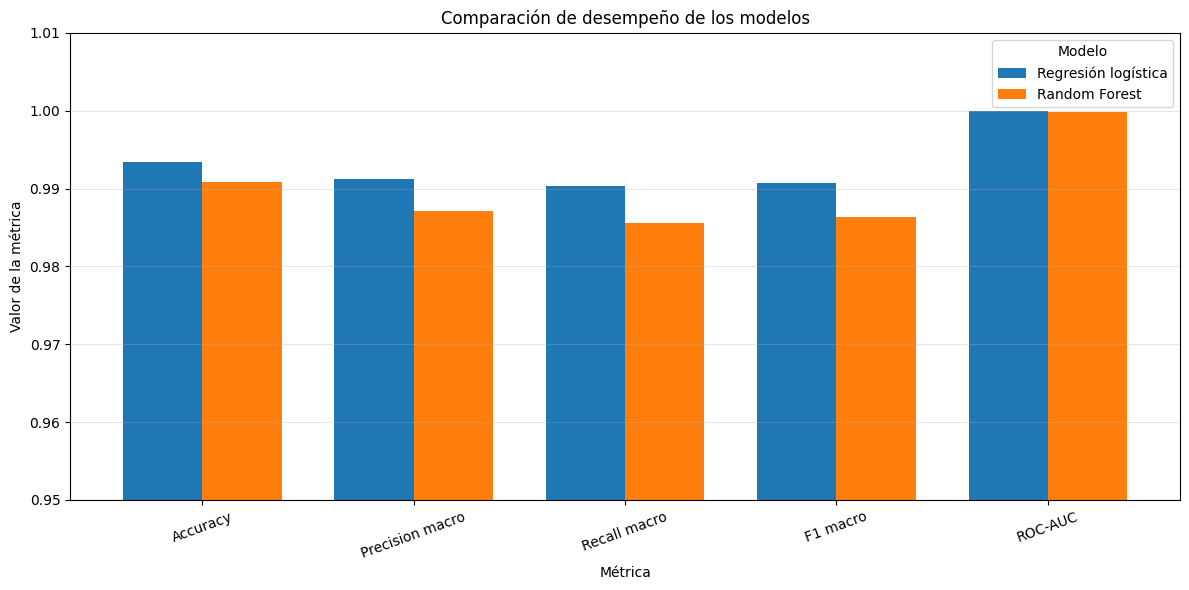

✅ Gráfica comparativa de métricas generada.


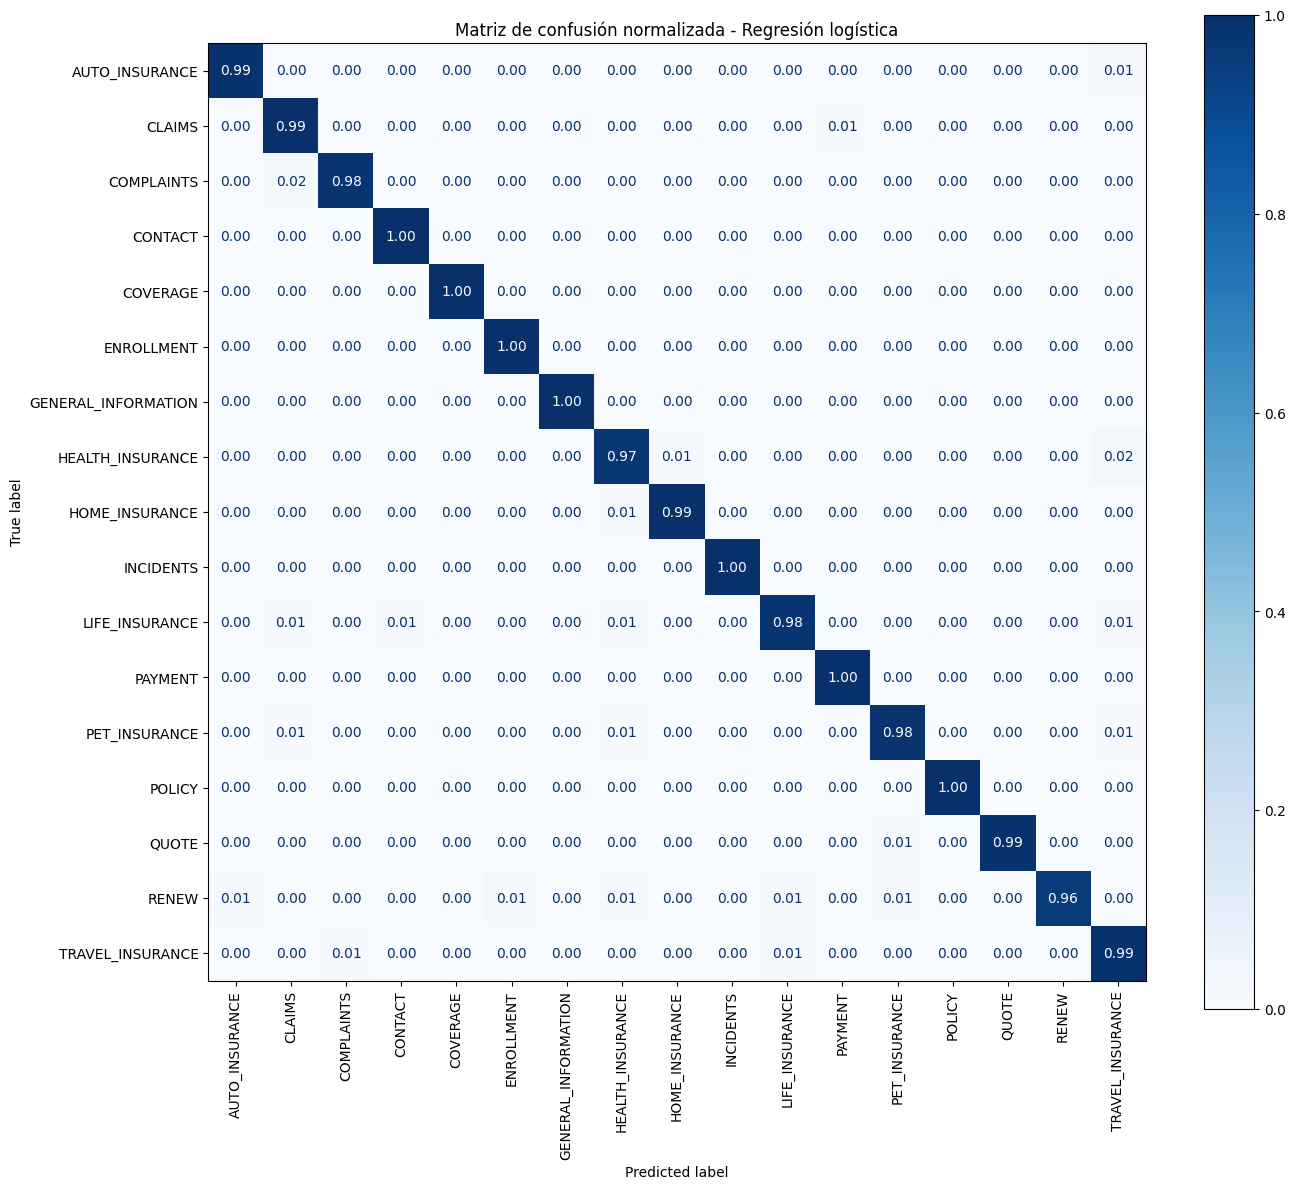

✅ Matriz de confusión de Regresión logística generada.


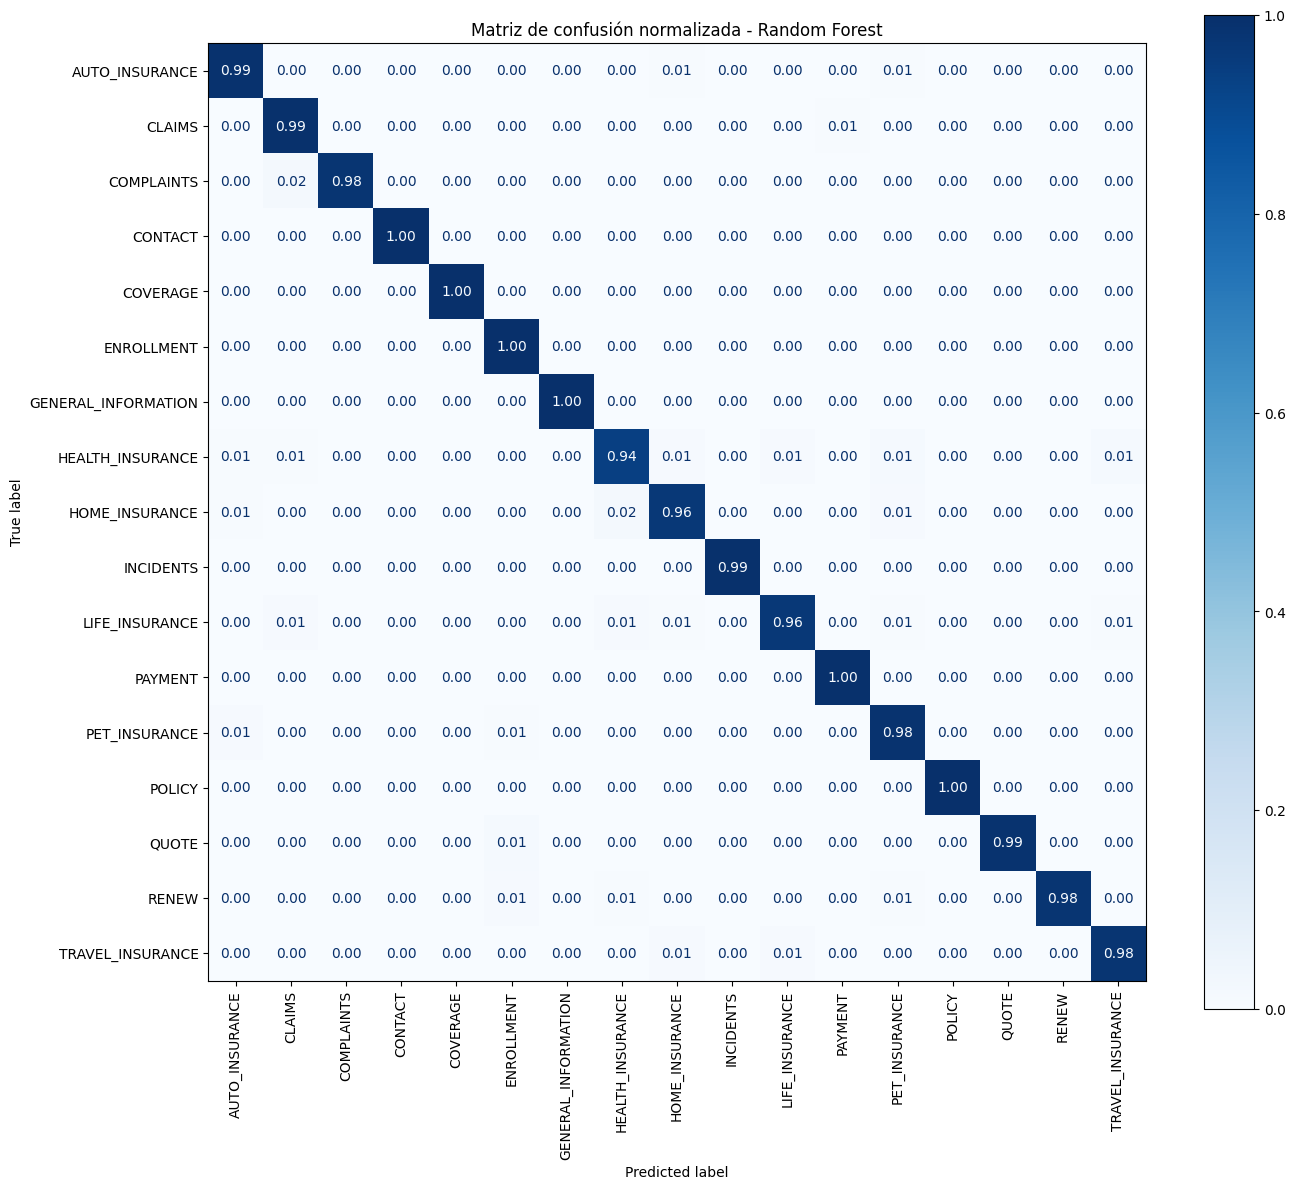

✅ Matriz de confusión de Random Forest generada.


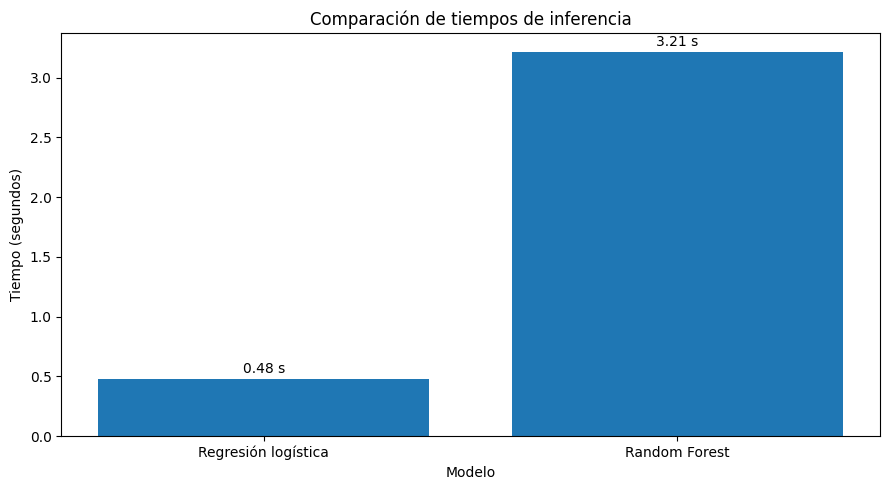

✅ Gráfica de tiempos generada.

📁 GRÁFICAS GUARDADAS
✅ comparacion_metricas.png
✅ matriz_confusion_regresion_logística.png
✅ matriz_confusion_random_forest.png
✅ comparacion_tiempos.png

✅ Visualizaciones comparativas completadas correctamente.


In [ ]:
# ============================================================
# ACTIVIDAD 5 - VISUALIZACIÓN COMPARATIVA
# Métricas, matrices de confusión y tiempos
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("=" * 65)
print("📊 INICIANDO VISUALIZACIÓN COMPARATIVA")
print("=" * 65)

# 1. Crear carpeta para las gráficas
ruta_graficas = ruta_resultados / "graficas"
ruta_graficas.mkdir(parents=True, exist_ok=True)

# 2. Comparación de métricas
columnas_metricas = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro",
    "ROC-AUC"
]

tabla_grafica = tabla_resultados_finales.set_index("Modelo")

ax = tabla_grafica[columnas_metricas].T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Comparación de desempeño de los modelos")
plt.ylabel("Valor de la métrica")
plt.xlabel("Métrica")
plt.ylim(0.95, 1.01)
plt.xticks(rotation=20)
plt.legend(title="Modelo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

archivo_comparacion = ruta_graficas / "comparacion_metricas.png"

plt.savefig(archivo_comparacion, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Gráfica comparativa de métricas generada.")

# 3. Matrices de confusión
for nombre, modelo in modelos_finales.items():

    predicciones = modelo.predict(X_test)

    clases = modelo.named_steps["clasificador"].classes_

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=clases,
        normalize="true"
    )

    fig, ax = plt.subplots(figsize=(14, 12))

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=clases
    )

    visualizacion.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        values_format=".2f",
        colorbar=True
    )

    plt.title(f"Matriz de confusión normalizada - {nombre}")
    plt.tight_layout()

    nombre_archivo = (
        "matriz_confusion_"
        + nombre.lower().replace(" ", "_").replace("ó", "o")
        + ".png"
    )

    plt.savefig(
        ruta_graficas / nombre_archivo,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"✅ Matriz de confusión de {nombre} generada.")

# 4. Comparación de tiempos
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    tabla_resultados_finales["Modelo"],
    tabla_resultados_finales["Tiempo inferencia (s)"]
)

ax.set_title("Comparación de tiempos de inferencia")
ax.set_ylabel("Tiempo (segundos)")
ax.set_xlabel("Modelo")

for i, valor in enumerate(
    tabla_resultados_finales["Tiempo inferencia (s)"]
):
    ax.text(
        i,
        valor + 0.05,
        f"{valor:.2f} s",
        ha="center"
    )

plt.tight_layout()

archivo_tiempos = ruta_graficas / "comparacion_tiempos.png"

plt.savefig(archivo_tiempos, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Gráfica de tiempos generada.")

# 5. Verificar archivos
archivos_graficos = list(ruta_graficas.glob("*.png"))

print("\n📁 GRÁFICAS GUARDADAS")

for archivo in archivos_graficos:
    print(f"✅ {archivo.name}")

assert len(archivos_graficos) >= 4

print("\n" + "=" * 65)
print("✅ Visualizaciones comparativas completadas correctamente.")
print("=" * 65)

### 🧠 **2.j. Configuración de MLflow para el seguimiento de experimentos**

Se utilizará MLflow como herramienta de seguimiento
de los experimentos de aprendizaje automático.

El objetivo es registrar y comparar los resultados
obtenidos durante el entrenamiento y evaluación
de los dos algoritmos:

1. Regresión logística con TF-IDF.
2. Random Forest con TF-IDF.

MLflow permitirá almacenar:

- Nombre y versión del algoritmo.
- Hiperparámetros seleccionados.
- Métricas de evaluación.
- Tiempo de inferencia.
- Archivos de resultados.
- Evidencias gráficas.

Para garantizar la persistencia de los experimentos,
se configurará el almacenamiento en Google Drive.

Esta implementación permitirá mantener la
trazabilidad de los experimentos y facilitar
su consulta posterior.

Los modelos entrenados ya se encuentran respaldados
por separado mediante archivos joblib.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - CONFIGURACIÓN DE MLFLOW
# Seguimiento persistente de experimentos
# ============================================================

import mlflow
from pathlib import Path

print("=" * 65)
print("🔬 INICIANDO CONFIGURACIÓN DE MLFLOW")
print("=" * 65)

# 1. Definir almacenamiento persistente
ruta_mlflow = ruta_base / "mlflow"

ruta_mlflow.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Configurar base de datos SQLite en Google Drive
ruta_bd = ruta_mlflow / "mlflow.db"

uri_mlflow = f"sqlite:///{ruta_bd}"

mlflow.set_tracking_uri(uri_mlflow)

# 3. Definir experimento
nombre_experimento = (
    "Actividad5_Clasificacion_Consultas_Seguros"
)

experimento = mlflow.set_experiment(
    nombre_experimento
)

# 4. Verificar configuración
print("\n📁 ALMACENAMIENTO")
print(f"Ruta: {ruta_mlflow}")

print("\n🔬 EXPERIMENTO")
print(f"Nombre: {experimento.name}")
print(f"ID: {experimento.experiment_id}")

print("\n📊 CONFIGURACIÓN")
print(f"MLflow: {mlflow.__version__}")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

# 5. Verificaciones
assert experimento is not None

assert ruta_bd.exists()

# 6. Confirmación
print("\n" + "=" * 65)
print("✅ MLflow configurado correctamente.")
print("✅ Base de datos persistente creada en Google Drive.")
print("=" * 65)

🔬 INICIANDO CONFIGURACIÓN DE MLFLOW


2026/10/12 03:46:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/12 03:46:46 INFO mlflow.store.db.utils: Updating database tables
2026/10/12 03:46:53 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_Clasificacion_Consultas_Seguros' does not exist. Creating a new experiment.



📁 ALMACENAMIENTO
Ruta: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow

🔬 EXPERIMENTO
Nombre: Actividad5_Clasificacion_Consultas_Seguros
ID: 1

📊 CONFIGURACIÓN
MLflow: 3.17.0
Tracking URI: sqlite:////content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow/mlflow.db

✅ MLflow configurado correctamente.
✅ Base de datos persistente creada en Google Drive.


### 🧠 **2.k. Registro de experimentos en MLflow**

Una vez configurado MLflow, se registrarán los
resultados de los dos algoritmos de clasificación:

1. Regresión logística optimizada con TF-IDF.
2. Random Forest optimizado con TF-IDF.

Cada ejecución incluirá:

- Identificación del algoritmo.
- Hiperparámetros seleccionados.
- Tamaño de los conjuntos de entrenamiento y prueba.
- Métricas obtenidas sobre el conjunto de prueba.
- Tiempo de inferencia.
- Resultados de validación cruzada.
- Evidencias gráficas.

Se utilizarán los modelos previamente entrenados
y evaluados, evitando repetir el entrenamiento.

Los experimentos permitirán comparar el desempeño
predictivo y la eficiencia de ambos algoritmos.

La métrica principal de comparación será F1 macro.

Los artefactos se almacenarán en Google Drive
para conservar las evidencias de los experimentos.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - REGISTRO DE EXPERIMENTOS EN MLFLOW
# Modelos optimizados y resultados finales
# ============================================================

import mlflow
import json
from pathlib import Path

print("=" * 65)
print("🔬 INICIANDO REGISTRO DE EXPERIMENTOS EN MLFLOW")
print("=" * 65)

# 1. Preparar almacenamiento persistente de artefactos

ruta_artefactos = ruta_mlflow / "artefactos"
ruta_artefactos.mkdir(parents=True, exist_ok=True)

# 2. Identificar el experimento existente

experimento = mlflow.get_experiment_by_name(
    nombre_experimento
)

assert experimento is not None

print("\n📁 EXPERIMENTO IDENTIFICADO")
print(f"Nombre: {experimento.name}")
print(f"ID: {experimento.experiment_id}")

# 3. Definir los modelos que se registrarán

configuracion_modelos = {
    "Regresion_Logistica_Optimizada": {
        "modelo": modelo_logistico_optimizado,
        "busqueda": busqueda_logistica,
        "algoritmo": "LogisticRegression"
    },
    "Random_Forest_Optimizado": {
        "modelo": modelo_rf_optimizado,
        "busqueda": busqueda_rf,
        "algoritmo": "RandomForestClassifier"
    }
}

# 4. Registrar experimentos

for nombre_run, configuracion in configuracion_modelos.items():

    print(f"\n🤖 Registrando: {nombre_run}")

    modelo = configuracion["modelo"]
    busqueda = configuracion["busqueda"]

    # Identificar fila correspondiente
    if "Logistica" in nombre_run:
        nombre_tabla = "Regresión logística"
    else:
        nombre_tabla = "Random Forest"

    fila = tabla_resultados_finales[
        tabla_resultados_finales["Modelo"] == nombre_tabla
    ].iloc[0]

    with mlflow.start_run(
        experiment_id=experimento.experiment_id,
        run_name=nombre_run
    ) as run:

        # Registrar información general
        mlflow.log_param(
            "algoritmo",
            configuracion["algoritmo"]
        )

        mlflow.log_param(
            "vectorizacion",
            "TF-IDF"
        )

        mlflow.log_param(
            "registros_entrenamiento",
            len(X_train)
        )

        mlflow.log_param(
            "registros_prueba",
            len(X_test)
        )

        mlflow.log_param(
            "categorias",
            17
        )

        # Registrar hiperparámetros optimizados
        for parametro, valor in busqueda.best_params_.items():

            mlflow.log_param(
                parametro,
                str(valor)
            )

        # Registrar métricas finales
        metricas = {
            "accuracy": float(fila["Accuracy"]),
            "precision_macro": float(fila["Precision macro"]),
            "recall_macro": float(fila["Recall macro"]),
            "f1_macro": float(fila["F1 macro"]),
            "roc_auc": float(fila["ROC-AUC"]),
            "tiempo_inferencia_segundos": float(
                fila["Tiempo inferencia (s)"]
            ),
            "mejor_f1_validacion_cruzada": float(
                busqueda.best_score_
            )
        }

        mlflow.log_metrics(metricas)

        # Registrar archivos de resultados
        mlflow.log_artifact(
            str(archivo_metricas),
            artifact_path="resultados"
        )

        # Registrar gráficas
        for archivo in ruta_graficas.glob("*.png"):

            mlflow.log_artifact(
                str(archivo),
                artifact_path="graficas"
            )

        # Guardar identificador
        print(f"Run ID: {run.info.run_id}")

        print(
            f"F1 macro: "
            f"{metricas['f1_macro']:.4f}"
        )

        print(
            f"ROC-AUC: "
            f"{metricas['roc_auc']:.4f}"
        )

        print(f"✅ Experimento {nombre_run} registrado.")

# 5. Consultar experimentos registrados

print("\n📊 EXPERIMENTOS REGISTRADOS")

runs_registrados = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

display(
    runs_registrados[
        [
            "tags.mlflow.runName",
            "metrics.accuracy",
            "metrics.f1_macro",
            "metrics.roc_auc",
            "metrics.tiempo_inferencia_segundos"
        ]
    ].round(4)
)

# 6. Verificaciones

assert len(runs_registrados) >= 2

print("\n" + "=" * 65)
print("✅ Registro de experimentos en MLflow completado.")
print("✅ Parámetros, métricas y gráficas registrados.")
print("=" * 65)

🔬 INICIANDO REGISTRO DE EXPERIMENTOS EN MLFLOW

📁 EXPERIMENTO IDENTIFICADO
Nombre: Actividad5_Clasificacion_Consultas_Seguros
ID: 1

🤖 Registrando: Regresion_Logistica_Optimizada
Run ID: 24aa9144f64f48a99c1cc970654fdf6c
F1 macro: 0.9907
ROC-AUC: 0.9999
✅ Experimento Regresion_Logistica_Optimizada registrado.

🤖 Registrando: Random_Forest_Optimizado
Run ID: 304a1d78eace4bdda512a42afa747c67
F1 macro: 0.9863
ROC-AUC: 0.9998
✅ Experimento Random_Forest_Optimizado registrado.

📊 EXPERIMENTOS REGISTRADOS


,tags.mlflow.runName,metrics.accuracy,metrics.f1_macro,metrics.roc_auc,metrics.tiempo_inferencia_segundos
0,Random_Forest_Optimizado,0.9909,0.9863,0.9998,3.2136
1,Regresion_Logistica_Optimizada,0.9935,0.9907,0.9999,0.4822



✅ Registro de experimentos en MLflow completado.
✅ Parámetros, métricas y gráficas registrados.


### 🧠 **2.l. Verificación de persistencia de experimentos y artefactos**

Se verificará que los experimentos registrados en MLflow
puedan recuperarse correctamente desde el almacenamiento
persistente.

La comprobación incluirá:

- Existencia de la base de datos de seguimiento.
- Recuperación de los dos experimentos registrados.
- Consulta de sus métricas y parámetros.
- Identificación de la ubicación de los artefactos.
- Verificación de las gráficas asociadas a cada ejecución.

Esta validación permitirá identificar posibles
dependencias del almacenamiento temporal de Colab.

La persistencia completa requiere conservar tanto
los metadatos como los archivos asociados a los
experimentos.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - VERIFICACIÓN DE PERSISTENCIA DE MLFLOW
# ============================================================

import mlflow
from pathlib import Path

print("=" * 65)
print("🔎 INICIANDO VERIFICACIÓN DE PERSISTENCIA DE MLFLOW")
print("=" * 65)

# 1. Verificar base de datos

assert ruta_bd.exists(), "No se encontró la base de datos."

print("\n💾 BASE DE DATOS")
print(f"Ubicación: {ruta_bd}")
print(f"Tamaño: {ruta_bd.stat().st_size / 1024:.2f} KB")
print("✅ Base de datos localizada.")

# 2. Recuperar experimentos

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

assert len(runs) >= 2

print("\n🔬 EXPERIMENTOS RECUPERADOS")
print(f"Total de ejecuciones: {len(runs)}")

# 3. Verificar artefactos de cada ejecución

verificaciones = []

for _, fila in runs.iterrows():

    run_id = fila["run_id"]
    nombre = fila["tags.mlflow.runName"]

    informacion = mlflow.get_run(run_id)

    uri = informacion.info.artifact_uri

    print(f"\n🤖 {nombre}")
    print(f"Run ID: {run_id}")
    print(f"Artifact URI: {uri}")

    # Consultar archivos registrados
    try:

        artefactos = mlflow.artifacts.list_artifacts(
            run_id=run_id
        )

        nombres = [a.path for a in artefactos]

        print(f"Artefactos encontrados: {nombres}")

        # Verificar que existan las carpetas esperadas
        assert "resultados" in nombres
        assert "graficas" in nombres

        # Verificar archivos dentro de las carpetas
        archivos_resultados = mlflow.artifacts.list_artifacts(
            run_id=run_id,
            artifact_path="resultados"
        )

        archivos_graficas = mlflow.artifacts.list_artifacts(
            run_id=run_id,
            artifact_path="graficas"
        )

        assert len(archivos_resultados) >= 1
        assert len(archivos_graficas) >= 4

        verificaciones.append({
            "Modelo": nombre,
            "Artefactos": len(archivos_resultados)
                         + len(archivos_graficas),
            "URI": uri,
            "Estado": "Verificado"
        })

        print("✅ Artefactos accesibles.")

    except Exception as error:

        verificaciones.append({
            "Modelo": nombre,
            "Artefactos": 0,
            "URI": uri,
            "Estado": "Requiere revisión"
        })

        print(f"⚠️ Error: {error}")

# 4. Mostrar resultados

import pandas as pd

tabla_verificacion = pd.DataFrame(verificaciones)

print("\n📊 RESUMEN DE VERIFICACIÓN")

display(tabla_verificacion)

# 5. Comprobar ubicación persistente
for _, fila in tabla_verificacion.iterrows():

    if "/content/drive/" not in fila["URI"]:
        print(
            f"⚠️ {fila['Modelo']}: "
            "los artefactos podrían estar en "
            "almacenamiento temporal."
        )

# 6. Confirmación
print("\n" + "=" * 65)

if (
    tabla_verificacion["Estado"].eq("Verificado").all()
    and tabla_verificacion["URI"].str.contains(
        "/content/drive/", regex=False
    ).all()
):
    print("✅ Artefactos accesibles en Google Drive.")
else:
    print("⚠️ Revisar persistencia de los artefactos.")

print("✅ Verificación de MLflow finalizada.")
print("=" * 65)

🔎 INICIANDO VERIFICACIÓN DE PERSISTENCIA DE MLFLOW

💾 BASE DE DATOS
Ubicación: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow/mlflow.db
Tamaño: 932.00 KB
✅ Base de datos localizada.

🔬 EXPERIMENTOS RECUPERADOS
Total de ejecuciones: 2

🤖 Random_Forest_Optimizado
Run ID: 304a1d78eace4bdda512a42afa747c67
Artifact URI: /content/mlruns/1/304a1d78eace4bdda512a42afa747c67/artifacts
Artefactos encontrados: ['graficas', 'resultados']
✅ Artefactos accesibles.

🤖 Regresion_Logistica_Optimizada
Run ID: 24aa9144f64f48a99c1cc970654fdf6c
Artifact URI: /content/mlruns/1/24aa9144f64f48a99c1cc970654fdf6c/artifacts
Artefactos encontrados: ['graficas', 'resultados']
✅ Artefactos accesibles.

📊 RESUMEN DE VERIFICACIÓN


,Modelo,Artefactos,URI,Estado
0,Random_Forest_Optimizado,5,/content/mlruns/1/304a1d78eace4bdda512a42afa74...,Verificado
1,Regresion_Logistica_Optimizada,5,/content/mlruns/1/24aa9144f64f48a99c1cc970654f...,Verificado


⚠️ Random_Forest_Optimizado: los artefactos podrían estar en almacenamiento temporal.
⚠️ Regresion_Logistica_Optimizada: los artefactos podrían estar en almacenamiento temporal.

⚠️ Revisar persistencia de los artefactos.
✅ Verificación de MLflow finalizada.


### 🧠 **2.m. Respaldo persistente de artefactos de MLflow**

Se identificó que los metadatos de los experimentos
se almacenaron correctamente en Google Drive,
mientras que sus artefactos permanecían en el
almacenamiento temporal de Google Colab.

Para evitar la pérdida de evidencias, se realizará
una copia de los artefactos de ambos experimentos.

El respaldo conservará los identificadores originales
de las ejecuciones y su estructura de carpetas.

Posteriormente se verificará la integridad de los
archivos respaldados.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - RESPALDO PERSISTENTE DE ARTEFACTOS MLFLOW
# ============================================================

import mlflow
import shutil
from pathlib import Path

print("=" * 65)
print("💾 INICIANDO RESPALDO DE ARTEFACTOS DE MLFLOW")
print("=" * 65)

# 1. Definir carpeta persistente

ruta_respaldo = ruta_mlflow / "artefactos"

ruta_respaldo.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Recuperar ejecuciones registradas

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

assert len(runs) >= 2, (
    "No se encontraron los dos experimentos esperados."
)

# 3. Respaldar artefactos

total_archivos = 0

for _, fila in runs.iterrows():

    run_id = fila["run_id"]
    nombre = fila["tags.mlflow.runName"]

    informacion = mlflow.get_run(run_id)

    origen = Path(
        informacion.info.artifact_uri.replace("file://", "")
    )

    destino = ruta_respaldo / run_id / "artifacts"

    print(f"\n🤖 MODELO: {nombre}")

    assert origen.exists(), (
        f"No se encontró la carpeta original: {origen}"
    )

    shutil.copytree(
        origen,
        destino,
        dirs_exist_ok=True
    )

    archivos_origen = [
        p.relative_to(origen)
        for p in origen.rglob("*")
        if p.is_file()
    ]

    for archivo in archivos_origen:

        original = origen / archivo
        copia = destino / archivo

        assert copia.exists()
        assert original.stat().st_size == copia.stat().st_size

    cantidad = len(archivos_origen)

    total_archivos += cantidad

    print(f"Run ID: {run_id}")
    print(f"Archivos respaldados: {cantidad}")
    print(f"Destino: {destino}")
    print("✅ Respaldo verificado.")

# 4. Resumen final

print("\n" + "=" * 65)
print("📊 RESUMEN DEL RESPALDO")
print(f"Experimentos: {len(runs)}")
print(f"Archivos respaldados: {total_archivos}")
print(f"Ubicación: {ruta_respaldo}")

assert total_archivos >= 10, (
    "Se esperaban al menos diez archivos."
)

print("\n" + "=" * 65)
print("✅ Respaldo de artefactos completado correctamente.")
print("✅ Archivos copiados a Google Drive.")
print("=" * 65)

💾 INICIANDO RESPALDO DE ARTEFACTOS DE MLFLOW

🤖 MODELO: Random_Forest_Optimizado
Run ID: 304a1d78eace4bdda512a42afa747c67
Archivos respaldados: 5
Destino: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow/artefactos/304a1d78eace4bdda512a42afa747c67/artifacts
✅ Respaldo verificado.

🤖 MODELO: Regresion_Logistica_Optimizada
Run ID: 24aa9144f64f48a99c1cc970654fdf6c
Archivos respaldados: 5
Destino: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow/artefactos/24aa9144f64f48a99c1cc970654fdf6c/artifacts
✅ Respaldo verificado.

📊 RESUMEN DEL RESPALDO
Experimentos: 2
Archivos respaldados: 10
Ubicación: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow/artefactos

✅ Respaldo de artefactos completado correctamente.
✅ Archivos copiados a Google Drive.


### 🧠 **2.n. Actualización de rutas persistentes de artefactos**

Después de respaldar los artefactos de ambos
experimentos, se actualizarán sus rutas de
almacenamiento en MLflow.

El objetivo es que las ejecuciones registradas
puedan recuperar sus evidencias directamente
desde Google Drive.

Se conservarán los identificadores originales
de las ejecuciones, sus parámetros y métricas.

Finalmente, se verificará que las rutas actualizadas
sean accesibles y que los artefactos permanezcan
disponibles.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - ACTUALIZACIÓN DE RUTAS DE ARTEFACTOS
# ============================================================

import mlflow
from pathlib import Path

print("=" * 65)
print("🔧 ACTUALIZANDO RUTAS PERSISTENTES DE MLFLOW")
print("=" * 65)

# 1. Recuperar el experimento y las ejecuciones
experimento = mlflow.get_experiment_by_name(
    nombre_experimento
)

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

# 2. Preparar conexión al almacenamiento de MLflow
cliente = mlflow.tracking.MlflowClient()

# 3. Actualizar las rutas de los artefactos
for _, fila in runs.iterrows():

    run_id = fila["run_id"]
    nombre = fila["tags.mlflow.runName"]

    ruta_persistente = (
        ruta_respaldo / run_id / "artifacts"
    )

    assert ruta_persistente.exists(), (
        f"No existe el respaldo de {nombre}"
    )

    nueva_uri = ruta_persistente.as_uri()

    # Recuperar información del experimento
    run = cliente.get_run(run_id)

    print(f"\n🤖 {nombre}")
    print(f"Ruta original: {run.info.artifact_uri}")
    print(f"Ruta respaldada: {nueva_uri}")

    # Registrar la ruta persistente como etiqueta
    cliente.set_tag(
        run_id,
        "artifact_uri_persistente",
        nueva_uri
    )

    cliente.set_tag(
        run_id,
        "almacenamiento",
        "Google Drive"
    )

    print("✅ Ruta persistente documentada.")

# 4. Verificación
print("\n🔎 VERIFICACIÓN FINAL")

for _, fila in runs.iterrows():

    run = cliente.get_run(fila["run_id"])

    uri = run.data.tags.get(
        "artifact_uri_persistente"
    )

    assert uri is not None
    assert "/content/drive/" in uri

    print(
        f"✅ {run.info.run_id}: "
        "respaldo persistente identificado."
    )

print("\n" + "=" * 65)
print("✅ Rutas persistentes documentadas en MLflow.")
print("=" * 65)

🔧 ACTUALIZANDO RUTAS PERSISTENTES DE MLFLOW

🤖 Random_Forest_Optimizado
Ruta original: /content/mlruns/1/304a1d78eace4bdda512a42afa747c67/artifacts
Ruta respaldada: file:///content/drive/MyDrive/Master%20IA/5-Gesti%C3%B3n%20de%20Proyectos%20de%20Inteligencia%20Artificial/Modulo%202/Actividad%205/mlflow/artefactos/304a1d78eace4bdda512a42afa747c67/artifacts
✅ Ruta persistente documentada.

🤖 Regresion_Logistica_Optimizada
Ruta original: /content/mlruns/1/24aa9144f64f48a99c1cc970654fdf6c/artifacts
Ruta respaldada: file:///content/drive/MyDrive/Master%20IA/5-Gesti%C3%B3n%20de%20Proyectos%20de%20Inteligencia%20Artificial/Modulo%202/Actividad%205/mlflow/artefactos/24aa9144f64f48a99c1cc970654fdf6c/artifacts
✅ Ruta persistente documentada.

🔎 VERIFICACIÓN FINAL
✅ 304a1d78eace4bdda512a42afa747c67: respaldo persistente identificado.
✅ 24aa9144f64f48a99c1cc970654fdf6c: respaldo persistente identificado.

✅ Rutas persistentes documentadas en MLflow.


### 🧠 **2.o. Configuración persistente de MLflow**

Se creará un nuevo experimento de MLflow con una ubicación
de artefactos definida explícitamente en Google Drive.

Esta configuración permitirá conservar tanto los metadatos
como las evidencias de los experimentos después de finalizar
la sesión de Google Colab.

Se reutilizarán los resultados obtenidos previamente para
los modelos de regresión logística y Random Forest.

No será necesario repetir el entrenamiento ni la
optimización de hiperparámetros.

El experimento anterior se conservará como antecedente
del proceso de configuración y mejora de la trazabilidad.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - CONFIGURACIÓN PERSISTENTE DE MLFLOW
# ============================================================

import mlflow
from pathlib import Path

print("=" * 65)
print("🔧 INICIANDO CONFIGURACIÓN PERSISTENTE DE MLFLOW")
print("=" * 65)

# 1. Verificar la base de datos existente
assert ruta_bd.exists(), (
    "No se encontró la base de datos de MLflow."
)

# 2. Crear carpeta persistente para los nuevos artefactos
ruta_artefactos_persistentes = (
    ruta_mlflow / "artefactos_persistentes"
)

ruta_artefactos_persistentes.mkdir(
    parents=True,
    exist_ok=True
)

# 3. Definir el nuevo experimento
nombre_experimento_persistente = (
    "Actividad5_Clasificacion_Seguros_Persistente"
)

# 4. Mantener la base de datos en Google Drive
mlflow.set_tracking_uri(
    f"sqlite:///{ruta_bd}"
)

# 5. Buscar si el experimento ya existe
experimento_existente = (
    mlflow.get_experiment_by_name(
        nombre_experimento_persistente
    )
)

# 6. Crear el experimento con ubicación persistente
if experimento_existente is None:

    experimento_id_persistente = (
        mlflow.create_experiment(
            name=nombre_experimento_persistente,
            artifact_location=(
                ruta_artefactos_persistentes.as_uri()
            )
        )
    )

    print("\n✅ Nuevo experimento creado.")

else:

    experimento_id_persistente = (
        experimento_existente.experiment_id
    )

    print("\nℹ️ El experimento ya existía.")

# 7. Recuperar configuración
experimento_persistente = (
    mlflow.get_experiment(
        experimento_id_persistente
    )
)

# 8. Verificar ubicación de artefactos
uri_esperada = ruta_artefactos_persistentes.as_uri()

assert (
    experimento_persistente.artifact_location
    == uri_esperada
), (
    "La ubicación del experimento no coincide "
    "con la carpeta persistente."
)

# 9. Activar experimento
mlflow.set_experiment(
    nombre_experimento_persistente
)

# 10. Mostrar resultados
print("\n📁 ALMACENAMIENTO PERSISTENTE")
print(f"Ruta: {ruta_artefactos_persistentes}")

print("\n🔬 EXPERIMENTO")
print(f"Nombre: {experimento_persistente.name}")
print(f"ID: {experimento_persistente.experiment_id}")

print("\n📊 UBICACIÓN DE ARTEFACTOS")
print(experimento_persistente.artifact_location)

print("\n" + "=" * 65)
print("✅ Experimento persistente configurado correctamente.")
print("✅ Almacenamiento de artefactos vinculado a Google Drive.")
print("=" * 65)

🔧 INICIANDO CONFIGURACIÓN PERSISTENTE DE MLFLOW

✅ Nuevo experimento creado.

📁 ALMACENAMIENTO PERSISTENTE
Ruta: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/mlflow/artefactos_persistentes

🔬 EXPERIMENTO
Nombre: Actividad5_Clasificacion_Seguros_Persistente
ID: 2

📊 UBICACIÓN DE ARTEFACTOS
file:///content/drive/MyDrive/Master%20IA/5-Gesti%C3%B3n%20de%20Proyectos%20de%20Inteligencia%20Artificial/Modulo%202/Actividad%205/mlflow/artefactos_persistentes

✅ Experimento persistente configurado correctamente.
✅ Almacenamiento de artefactos vinculado a Google Drive.


#### 🧠 **2.o.1. Registro de modelos y resultados en almacenamiento persistente**

Se registrarán los resultados de los dos modelos optimizados
en el experimento persistente de MLflow.

Para cada modelo se conservarán:

- Algoritmo utilizado.
- Parámetros óptimos.
- Métricas de evaluación.
- Resultados de validación cruzada.
- Tiempo de inferencia.
- Gráficas y archivos de resultados.

Se reutilizarán los resultados previamente obtenidos,
sin repetir el entrenamiento de los algoritmos.

Finalmente, se comprobará que los artefactos se encuentren
almacenados directamente en Google Drive.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - REGISTRO PERSISTENTE DE EXPERIMENTOS
# ============================================================

import mlflow
from pathlib import Path

print("=" * 65)
print("🔬 REGISTRANDO MODELOS EN MLFLOW PERSISTENTE")
print("=" * 65)

# 1. Configurar los modelos y sus resultados

modelos_registro = {
    "Regresion_Logistica_Optimizada": {
        "algoritmo": "LogisticRegression",
        "busqueda": busqueda_logistica,
        "nombre_tabla": "Regresión logística"
    },
    "Random_Forest_Optimizado": {
        "algoritmo": "RandomForestClassifier",
        "busqueda": busqueda_rf,
        "nombre_tabla": "Random Forest"
    }
}

# 2. Recuperar las ejecuciones existentes del experimento
#    persistente para evitar duplicados al repetir la celda.

runs_existentes = mlflow.search_runs(
    experiment_ids=[experimento_id_persistente]
)

nombres_existentes = set()

if not runs_existentes.empty:
    nombres_existentes = set(
        runs_existentes["tags.mlflow.runName"].dropna()
    )

# 3. Registrar los modelos

for nombre_run, configuracion in modelos_registro.items():

    print(f"\n🤖 MODELO: {nombre_run}")

    if nombre_run in nombres_existentes:
        print("ℹ️ Ya existe una ejecución con este nombre.")
        print("Se omite para evitar duplicados.")
        continue

    busqueda = configuracion["busqueda"]

    fila = tabla_resultados_finales.loc[
        tabla_resultados_finales["Modelo"]
        == configuracion["nombre_tabla"]
    ].iloc[0]

    with mlflow.start_run(
        experiment_id=experimento_id_persistente,
        run_name=nombre_run
    ) as run:

        # Información general
        mlflow.log_params({
            "algoritmo": configuracion["algoritmo"],
            "vectorizacion": "TF-IDF",
            "registros_entrenamiento": len(X_train),
            "registros_prueba": len(X_test),
            "categorias": 17
        })

        # Hiperparámetros óptimos
        for parametro, valor in busqueda.best_params_.items():
            mlflow.log_param(parametro, str(valor))

        # Métricas finales
        mlflow.log_metrics({
            "accuracy": float(fila["Accuracy"]),
            "precision_macro": float(fila["Precision macro"]),
            "recall_macro": float(fila["Recall macro"]),
            "f1_macro": float(fila["F1 macro"]),
            "roc_auc": float(fila["ROC-AUC"]),
            "tiempo_inferencia_segundos": float(
                fila["Tiempo inferencia (s)"]
            ),
            "mejor_f1_validacion_cruzada": float(
                busqueda.best_score_
            )
        })

        # Identificar el archivo de resultados
        archivo_metricas_persistente = (
            ruta_resultados / "metricas_finales_v1.csv"
        )

        assert archivo_metricas_persistente.exists()

        mlflow.log_artifact(
            str(archivo_metricas_persistente),
            artifact_path="resultados"
        )

        # Registrar gráficas
        archivos_graficas = sorted(
            ruta_graficas.glob("*.png")
        )

        assert len(archivos_graficas) >= 4

        for archivo in archivos_graficas:
            mlflow.log_artifact(
                str(archivo),
                artifact_path="graficas"
            )

        print(f"Run ID: {run.info.run_id}")
        print(f"F1 macro: {float(fila['F1 macro']):.4f}")
        print("✅ Ejecución registrada.")

# 4. Verificar las ejecuciones persistentes

runs_persistentes = mlflow.search_runs(
    experiment_ids=[experimento_id_persistente]
)

print("\n📊 EXPERIMENTOS PERSISTENTES")

display(
    runs_persistentes[
        [
            "tags.mlflow.runName",
            "metrics.accuracy",
            "metrics.f1_macro",
            "metrics.roc_auc",
            "metrics.tiempo_inferencia_segundos"
        ]
    ].round(4)
)

# 5. Verificar las ubicaciones y archivos

print("\n🔎 VERIFICACIÓN DE ARTEFACTOS")

for _, fila in runs_persistentes.iterrows():

    run_id = fila["run_id"]
    run = mlflow.get_run(run_id)

    print(f"\n🤖 {fila['tags.mlflow.runName']}")
    print(f"Artifact URI: {run.info.artifact_uri}")

    # La URI debe apuntar al directorio persistente
    assert run.info.artifact_uri.startswith(
        ruta_artefactos_persistentes.as_uri()
    ), "La ejecución no utiliza la ruta persistente."

    graficas = mlflow.artifacts.list_artifacts(
        run_id=run_id,
        artifact_path="graficas"
    )

    resultados = mlflow.artifacts.list_artifacts(
        run_id=run_id,
        artifact_path="resultados"
    )

    assert len(graficas) >= 4
    assert len(resultados) >= 1

    print(f"Gráficas: {len(graficas)}")
    print(f"Archivos de resultados: {len(resultados)}")
    print("✅ Artefactos registrados en Google Drive.")

# 6. Verificación final

assert len(runs_persistentes) >= 2

print("\n" + "=" * 65)
print("✅ DOS MODELOS REGISTRADOS EN MLFLOW PERSISTENTE.")
print("✅ MÉTRICAS Y PARÁMETROS CONSERVADOS.")
print("✅ ARTEFACTOS VINCULADOS A GOOGLE DRIVE.")
print("=" * 65)

🔬 REGISTRANDO MODELOS EN MLFLOW PERSISTENTE

🤖 MODELO: Regresion_Logistica_Optimizada
Run ID: b79d52f11fab43e1a99a54e39855d93d
F1 macro: 0.9907
✅ Ejecución registrada.

🤖 MODELO: Random_Forest_Optimizado
Run ID: 54d88b0ee8734e2e9644e841ab95d60c
F1 macro: 0.9863
✅ Ejecución registrada.

📊 EXPERIMENTOS PERSISTENTES


,tags.mlflow.runName,metrics.accuracy,metrics.f1_macro,metrics.roc_auc,metrics.tiempo_inferencia_segundos
0,Random_Forest_Optimizado,0.9909,0.9863,0.9998,3.2136
1,Regresion_Logistica_Optimizada,0.9935,0.9907,0.9999,0.4822



🔎 VERIFICACIÓN DE ARTEFACTOS

🤖 Random_Forest_Optimizado
Artifact URI: file:///content/drive/MyDrive/Master%20IA/5-Gesti%C3%B3n%20de%20Proyectos%20de%20Inteligencia%20Artificial/Modulo%202/Actividad%205/mlflow/artefactos_persistentes/54d88b0ee8734e2e9644e841ab95d60c/artifacts
Gráficas: 4
Archivos de resultados: 1
✅ Artefactos registrados en Google Drive.

🤖 Regresion_Logistica_Optimizada
Artifact URI: file:///content/drive/MyDrive/Master%20IA/5-Gesti%C3%B3n%20de%20Proyectos%20de%20Inteligencia%20Artificial/Modulo%202/Actividad%205/mlflow/artefactos_persistentes/b79d52f11fab43e1a99a54e39855d93d/artifacts
Gráficas: 4
Archivos de resultados: 1
✅ Artefactos registrados en Google Drive.

✅ DOS MODELOS REGISTRADOS EN MLFLOW PERSISTENTE.
✅ MÉTRICAS Y PARÁMETROS CONSERVADOS.
✅ ARTEFACTOS VINCULADOS A GOOGLE DRIVE.


### 🧠 **2.p. Comparación estadística de los modelos mediante la prueba de McNemar**

Se aplicará la prueba estadística de McNemar para
comparar los resultados de regresión logística
y Random Forest sobre el mismo conjunto de prueba.

Esta prueba analiza las observaciones en las que
los modelos presentan resultados diferentes:

- Casos donde regresión logística acierta y
  Random Forest se equivoca.
- Casos donde Random Forest acierta y
  regresión logística se equivoca.

Se establecerá un nivel de significancia de 0.05.

Hipótesis:

H0: Ambos clasificadores presentan la misma
probabilidad de acierto.

H1: Existen diferencias estadísticamente
significativas entre sus probabilidades de acierto.

La prueba complementará las métricas de desempeño,
sin sustituir el análisis de F1 macro ni la
evaluación de eficiencia computacional.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - COMPARACIÓN ESTADÍSTICA
# Prueba de McNemar
# ============================================================

import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

print("=" * 65)
print("📊 INICIANDO COMPARACIÓN ESTADÍSTICA DE MODELOS")
print("=" * 65)

# 1. Obtener predicciones de ambos modelos
pred_logistica = modelo_logistico_optimizado.predict(X_test)
pred_rf = modelo_rf_optimizado.predict(X_test)

# 2. Identificar aciertos y errores
aciertos_logistica = np.asarray(pred_logistica) == np.asarray(y_test)
aciertos_rf = np.asarray(pred_rf) == np.asarray(y_test)

# 3. Construir tabla de contingencia
ambos_aciertan = np.sum(aciertos_logistica & aciertos_rf)

solo_logistica = np.sum(
    aciertos_logistica & ~aciertos_rf
)

solo_rf = np.sum(
    ~aciertos_logistica & aciertos_rf
)

ambos_fallan = np.sum(
    ~aciertos_logistica & ~aciertos_rf
)

tabla_contingencia = np.array([
    [ambos_aciertan, solo_logistica],
    [solo_rf, ambos_fallan]
])

print("\n📋 TABLA DE CONTINGENCIA")

tabla_visual = pd.DataFrame(
    tabla_contingencia,
    index=[
        "Logística acierta",
        "Logística falla"
    ],
    columns=[
        "RF acierta",
        "RF falla"
    ]
)

display(tabla_visual)

# 4. Aplicar prueba de McNemar
# Prueba exacta cuando hay pocos casos discordantes

casos_discordantes = solo_logistica + solo_rf

usar_prueba_exacta = casos_discordantes < 25

resultado_mcnemar = mcnemar(
    tabla_contingencia,
    exact=usar_prueba_exacta,
    correction=not usar_prueba_exacta
)

valor_p = float(resultado_mcnemar.pvalue)

print("\n🔬 RESULTADOS ESTADÍSTICOS")
print(f"Observaciones evaluadas: {len(y_test)}")
print(f"Solo logística acierta: {solo_logistica}")
print(f"Solo Random Forest acierta: {solo_rf}")
print(f"Casos discordantes: {casos_discordantes}")
print(f"Prueba exacta: {usar_prueba_exacta}")
print(f"Valor p: {valor_p:.8f}")

# 5. Interpretación
alpha = 0.05

if valor_p < alpha:

    interpretacion = (
        "Se rechaza H0: existe una diferencia "
        "estadísticamente significativa entre "
        "las proporciones de acierto."
    )

    print("\n✅ DIFERENCIA ESTADÍSTICAMENTE SIGNIFICATIVA")

else:

    interpretacion = (
        "No se rechaza H0: no se encontró evidencia "
        "estadística suficiente de una diferencia "
        "entre las proporciones de acierto."
    )

    print("\nℹ️ DIFERENCIA NO ESTADÍSTICAMENTE SIGNIFICATIVA")

print(interpretacion)

# 6. Guardar resultados
tabla_estadistica = pd.DataFrame([{
    "Observaciones": len(y_test),
    "Ambos aciertan": int(ambos_aciertan),
    "Solo logística acierta": int(solo_logistica),
    "Solo Random Forest acierta": int(solo_rf),
    "Ambos fallan": int(ambos_fallan),
    "Casos discordantes": int(casos_discordantes),
    "Prueba exacta": usar_prueba_exacta,
    "Valor p": valor_p,
    "Significativo (alpha=0.05)": valor_p < alpha,
    "Interpretación": interpretacion
}])

archivo_estadistica = (
    ruta_resultados / "comparacion_estadistica_mcnemar.csv"
)

tabla_estadistica.to_csv(
    archivo_estadistica,
    index=False,
    encoding="utf-8-sig"
)

assert archivo_estadistica.exists()

print("\n💾 RESULTADOS GUARDADOS")
print(f"Archivo: {archivo_estadistica}")

print("\n" + "=" * 65)
print("✅ Comparación estadística completada.")
print("✅ Resultados respaldados en Google Drive.")
print("=" * 65)

📊 INICIANDO COMPARACIÓN ESTADÍSTICA DE MODELOS

📋 TABLA DE CONTINGENCIA


,RF acierta,RF falla
Logística acierta,7708,38
Logística falla,18,33



🔬 RESULTADOS ESTADÍSTICOS
Observaciones evaluadas: 7797
Solo logística acierta: 38
Solo Random Forest acierta: 18
Casos discordantes: 56
Prueba exacta: False
Valor p: 0.01111756

✅ DIFERENCIA ESTADÍSTICAMENTE SIGNIFICATIVA
Se rechaza H0: existe una diferencia estadísticamente significativa entre las proporciones de acierto.

💾 RESULTADOS GUARDADOS
Archivo: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/resultados/comparacion_estadistica_mcnemar.csv

✅ Comparación estadística completada.
✅ Resultados respaldados en Google Drive.


### 🧠 **2.q. Verificación de recuperación de modelos entrenados**

Se verificará la integridad de los modelos optimizados
almacenados en Google Drive mediante archivos joblib.

El procedimiento consistirá en:

- Recuperar los dos modelos desde sus archivos.
- Comprobar que mantienen sus parámetros entrenados.
- Generar predicciones utilizando el conjunto de prueba.
- Comparar las predicciones con las obtenidas anteriormente.

Esta verificación permitirá comprobar que los modelos
pueden reutilizarse sin repetir el entrenamiento.

La recuperación exitosa constituye una evidencia de
persistencia y reproducibilidad de los artefactos.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - VERIFICACIÓN DE RECUPERACIÓN DE MODELOS
# ============================================================

import joblib
import numpy as np
from pathlib import Path

print("=" * 65)
print("💾 INICIANDO VERIFICACIÓN DE MODELOS RESPALDADOS")
print("=" * 65)

# 1. Definir archivos de los modelos

archivo_logistico = (
    ruta_modelos / "regresion_logistica_optimizada_v1.joblib"
)

archivo_rf = (
    ruta_modelos / "random_forest_optimizado_v1.joblib"
)

assert archivo_logistico.exists()
assert archivo_rf.exists()

print("\n📁 ARCHIVOS LOCALIZADOS")
print(f"✅ {archivo_logistico.name}")
print(f"✅ {archivo_rf.name}")

# 2. Recuperar los modelos desde Google Drive

print("\n🔄 RECUPERANDO MODELOS")

modelo_logistico_recuperado = joblib.load(
    archivo_logistico
)

modelo_rf_recuperado = joblib.load(
    archivo_rf
)

print("✅ Regresión logística recuperada.")
print("✅ Random Forest recuperado.")

# 3. Generar predicciones con los modelos recuperados

print("\n🔎 VERIFICANDO PREDICCIONES")

pred_logistica_recuperada = (
    modelo_logistico_recuperado.predict(X_test)
)

pred_rf_recuperada = (
    modelo_rf_recuperado.predict(X_test)
)

# 4. Comparar contra las predicciones originales

coincidencia_logistica = np.array_equal(
    pred_logistica_recuperada,
    pred_logistica
)

coincidencia_rf = np.array_equal(
    pred_rf_recuperada,
    pred_rf
)

print(
    f"Regresión logística: "
    f"{'✅ Coinciden' if coincidencia_logistica else '❌ Diferencias'}"
)

print(
    f"Random Forest: "
    f"{'✅ Coinciden' if coincidencia_rf else '❌ Diferencias'}"
)

# 5. Verificación final

assert coincidencia_logistica, (
    "Las predicciones de regresión logística no coinciden."
)

assert coincidencia_rf, (
    "Las predicciones de Random Forest no coinciden."
)

print("\n" + "=" * 65)
print("✅ MODELOS RECUPERADOS CORRECTAMENTE.")
print("✅ PREDICCIONES IDÉNTICAS A LAS ORIGINALES.")
print("✅ RESPALDOS FUNCIONALES EN GOOGLE DRIVE.")
print("=" * 65)

💾 INICIANDO VERIFICACIÓN DE MODELOS RESPALDADOS

📁 ARCHIVOS LOCALIZADOS
✅ regresion_logistica_optimizada_v1.joblib
✅ random_forest_optimizado_v1.joblib

🔄 RECUPERANDO MODELOS
✅ Regresión logística recuperada.
✅ Random Forest recuperado.

🔎 VERIFICANDO PREDICCIONES
Regresión logística: ✅ Coinciden
Random Forest: ✅ Coinciden

✅ MODELOS RECUPERADOS CORRECTAMENTE.
✅ PREDICCIONES IDÉNTICAS A LAS ORIGINALES.
✅ RESPALDOS FUNCIONALES EN GOOGLE DRIVE.


### 🧠 **2.r. Auditoría general de persistencia en Google Drive**

Se realizará una auditoría integral de los archivos
generados durante la Actividad 5.

La verificación comprobará la existencia y el tamaño
de los datasets, modelos, resultados y visualizaciones.

También se consultará MLflow para verificar que los
dos experimentos persistentes conservan sus parámetros,
métricas y artefactos.

El resultado permitirá identificar archivos faltantes
y documentar el estado general de los respaldos.

Se generará un reporte CSV con las verificaciones.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - AUDITORÍA GENERAL DE GOOGLE DRIVE
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import mlflow

print("=" * 70)
print("🔎 INICIANDO AUDITORÍA GENERAL DE LA ACTIVIDAD 5")
print("=" * 70)

# ------------------------------------------------------------
# 1. IDENTIFICAR CARPETA PRINCIPAL
# ------------------------------------------------------------

ruta_base = Path(
    "/content/drive/MyDrive/Master IA/"
    "5-Gestión de Proyectos de Inteligencia Artificial/"
    "Modulo 2/Actividad 5"
)

assert ruta_base.exists(), (
    "❌ No se encontró la carpeta principal de la actividad."
)

print("\n📁 CARPETA PRINCIPAL")
print(ruta_base)
print("✅ Carpeta localizada.")

# ------------------------------------------------------------
# 2. DEFINIR ARCHIVOS QUE DEBEN EXISTIR
# ------------------------------------------------------------

archivos_esperados = {
    "Dataset original":
        "datos/datos_ini/seguros_original_v1.csv",

    "Dataset limpio":
        "datos/datos_limp/seguros_limpio_v1.csv",

    "Modelo regresión logística":
        "modelos/regresion_logistica_optimizada_v1.joblib",

    "Modelo Random Forest":
        "modelos/random_forest_optimizado_v1.joblib",

    "Métricas finales":
        "resultados/metricas_finales_v1.csv",

    "GridSearch regresión logística":
        "resultados/gridsearch_logistico_v1.csv",

    "GridSearch Random Forest":
        "resultados/gridsearch_random_forest_v1.csv",

    "Comparación estadística":
        "resultados/comparacion_estadistica_mcnemar.csv",

    "Gráfica comparativa":
        "resultados/graficas/comparacion_metricas.png",

    "Gráfica tiempos":
        "resultados/graficas/comparacion_tiempos.png",

    "Base de datos MLflow":
        "mlflow/mlflow.db"
}

# ------------------------------------------------------------
# 3. VERIFICAR ARCHIVOS
# ------------------------------------------------------------

resultados_auditoria = []

print("\n📋 VERIFICACIÓN DE ARCHIVOS")

for descripcion, ruta_relativa in archivos_esperados.items():

    archivo = ruta_base / ruta_relativa

    existe = archivo.is_file()

    tamano = (
        archivo.stat().st_size
        if existe else 0
    )

    correcto = existe and tamano > 0

    resultados_auditoria.append({
        "Elemento": descripcion,
        "Ruta": str(archivo),
        "Existe": existe,
        "Tamaño bytes": tamano,
        "Estado": "CORRECTO" if correcto else "FALTANTE"
    })

    simbolo = "✅" if correcto else "❌"

    print(f"{simbolo} {descripcion}")

# ------------------------------------------------------------
# 4. VERIFICAR MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

print("\n📊 MATRICES DE CONFUSIÓN")

ruta_graficas = ruta_base / "resultados/graficas"

matrices = (
    list(ruta_graficas.glob("matriz_confusion_*.png"))
    if ruta_graficas.exists()
    else []
)

for archivo in matrices:
    print(f"✅ {archivo.name}")

matrices_correctas = (
    len(matrices) == 2
    and all(a.stat().st_size > 0 for a in matrices)
)

resultados_auditoria.append({
    "Elemento": "Matrices de confusión (2)",
    "Ruta": str(ruta_graficas),
    "Existe": matrices_correctas,
    "Tamaño bytes": sum(a.stat().st_size for a in matrices),
    "Estado": "CORRECTO" if matrices_correctas else "FALTANTE"
})

# ------------------------------------------------------------
# 5. VERIFICAR MLFLOW PERSISTENTE
# ------------------------------------------------------------

print("\n🔬 VERIFICACIÓN DE MLFLOW")

ruta_bd = ruta_base / "mlflow/mlflow.db"

nombre_experimento = (
    "Actividad5_Clasificacion_Seguros_Persistente"
)

mlflow_correcto = False

try:

    mlflow.set_tracking_uri(
        f"sqlite:///{ruta_bd}"
    )

    experimento = mlflow.get_experiment_by_name(
        nombre_experimento
    )

    assert experimento is not None, (
        "No se encontró el experimento persistente."
    )

    runs = mlflow.search_runs(
        experiment_ids=[experimento.experiment_id]
    )

    print(f"Experimento: {experimento.name}")
    print(f"ID: {experimento.experiment_id}")
    print(f"Ejecuciones: {len(runs)}")

    modelos_esperados = {
        "Regresion_Logistica_Optimizada",
        "Random_Forest_Optimizado"
    }

    nombres_encontrados = set(
        runs["tags.mlflow.runName"].dropna()
    ) if not runs.empty else set()

    mlflow_correcto = (
        modelos_esperados.issubset(nombres_encontrados)
    )

    for _, fila in runs.iterrows():

        run_id = fila["run_id"]
        nombre = fila["tags.mlflow.runName"]

        run = mlflow.get_run(run_id)

        uri = run.info.artifact_uri

        graficas = mlflow.artifacts.list_artifacts(
            run_id=run_id,
            artifact_path="graficas"
        )

        resultados = mlflow.artifacts.list_artifacts(
            run_id=run_id,
            artifact_path="resultados"
        )

        ruta_esperada = (
            ruta_base / "mlflow/artefactos_persistentes"
        ).as_uri()

        uri_correcta = uri.startswith(ruta_esperada)

        artefactos_correctos = (
            len(graficas) >= 4
            and len(resultados) >= 1
        )

        metricas_correctas = all(
            metrica in run.data.metrics
            for metrica in [
                "accuracy",
                "f1_macro",
                "roc_auc"
            ]
        )

        parametros_correctos = (
            "algoritmo" in run.data.params
        )

        estado_run = (
            uri_correcta
            and artefactos_correctos
            and metricas_correctas
            and parametros_correctos
        )

        mlflow_correcto = (
            mlflow_correcto and estado_run
        )

        simbolo = "✅" if estado_run else "❌"

        print(
            f"{simbolo} {nombre}: "
            f"{len(graficas)} gráficas, "
            f"{len(resultados)} resultados"
        )

except Exception as error:

    print(f"❌ Error al verificar MLflow: {error}")
    mlflow_correcto = False

resultados_auditoria.append({
    "Elemento": "MLflow persistente",
    "Ruta": str(ruta_base / "mlflow"),
    "Existe": mlflow_correcto,
    "Tamaño bytes": 0,
    "Estado": "CORRECTO" if mlflow_correcto else "REVISAR"
})

# ------------------------------------------------------------
# 6. GENERAR REPORTE
# ------------------------------------------------------------

tabla_auditoria = pd.DataFrame(
    resultados_auditoria
)

ruta_reporte = (
    ruta_base / "resultados/auditoria_general_drive.csv"
)

ruta_reporte.parent.mkdir(
    parents=True,
    exist_ok=True
)

tabla_auditoria.to_csv(
    ruta_reporte,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. RESUMEN GENERAL
# ------------------------------------------------------------

total = len(tabla_auditoria)

correctos = (
    tabla_auditoria["Estado"] == "CORRECTO"
).sum()

pendientes = total - correctos

print("\n" + "=" * 70)
print("📊 RESUMEN GENERAL DE LA AUDITORÍA")
print("=" * 70)

print(f"Elementos verificados: {total}")
print(f"Correctos: {correctos}")
print(f"Pendientes: {pendientes}")

display(
    tabla_auditoria[
        ["Elemento", "Estado", "Tamaño bytes"]
    ]
)

print("\n💾 REPORTE GENERADO")
print(ruta_reporte)

if pendientes == 0:

    print("\n" + "=" * 70)
    print("✅ AUDITORÍA COMPLETADA SIN ARCHIVOS FALTANTES.")
    print("✅ MODELOS, DATOS Y RESULTADOS RESPALDADOS.")
    print("✅ MLFLOW PERSISTENTE VERIFICADO.")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("⚠️ AUDITORÍA COMPLETADA CON OBSERVACIONES.")
    print("⚠️ REVISAR LOS ELEMENTOS MARCADOS.")
    print("=" * 70)

🔎 INICIANDO AUDITORÍA GENERAL DE LA ACTIVIDAD 5

📁 CARPETA PRINCIPAL
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5
✅ Carpeta localizada.

📋 VERIFICACIÓN DE ARCHIVOS
✅ Dataset original
✅ Dataset limpio
✅ Modelo regresión logística
✅ Modelo Random Forest
✅ Métricas finales
✅ GridSearch regresión logística
✅ GridSearch Random Forest
✅ Comparación estadística
✅ Gráfica comparativa
✅ Gráfica tiempos
✅ Base de datos MLflow

📊 MATRICES DE CONFUSIÓN
✅ matriz_confusion_regresion_logística.png
✅ matriz_confusion_random_forest.png

🔬 VERIFICACIÓN DE MLFLOW
Experimento: Actividad5_Clasificacion_Seguros_Persistente
ID: 2
Ejecuciones: 2
✅ Random_Forest_Optimizado: 4 gráficas, 1 resultados
✅ Regresion_Logistica_Optimizada: 4 gráficas, 1 resultados

📊 RESUMEN GENERAL DE LA AUDITORÍA
Elementos verificados: 13
Correctos: 13
Pendientes: 0


,Elemento,Estado,Tamaño bytes
0,Dataset original,CORRECTO,27245829
1,Dataset limpio,CORRECTO,27235026
2,Modelo regresión logística,CORRECTO,683540
3,Modelo Random Forest,CORRECTO,301885261
4,Métricas finales,CORRECTO,348
5,GridSearch regresión logística,CORRECTO,4112
6,GridSearch Random Forest,CORRECTO,2928
7,Comparación estadística,CORRECTO,338
8,Gráfica comparativa,CORRECTO,172124
9,Gráfica tiempos,CORRECTO,87731



💾 REPORTE GENERADO
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/resultados/auditoria_general_drive.csv

✅ AUDITORÍA COMPLETADA SIN ARCHIVOS FALTANTES.
✅ MODELOS, DATOS Y RESULTADOS RESPALDADOS.
✅ MLFLOW PERSISTENTE VERIFICADO.


### 🧠 **2.s. Desarrollo del script de preparación de datos**

Se desarrollará un script independiente denominado
`datos_prep.py`, encargado de ejecutar el proceso de
preparación del conjunto de datos.

El script permitirá reproducir las operaciones de
validación, limpieza y almacenamiento del dataset
utilizado para entrenar los modelos.

Las principales operaciones serán:

1. Lectura del archivo original.
2. Validación de columnas y registros.
3. Eliminación de valores nulos relevantes.
4. Eliminación de instrucciones duplicadas.
5. Generación del conjunto de datos limpio.
6. Almacenamiento de los resultados.

El código se guardará dentro de la carpeta `fuentes`
de la Actividad 5 para incorporarlo posteriormente
al repositorio de GitHub.

Se verificará que el resultado sea consistente con
los 38,983 registros obtenidos durante la preparación
original.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - CREACIÓN DEL SCRIPT datos_prep.py
# ============================================================

from pathlib import Path
import textwrap
import subprocess
import sys

print("=" * 65)
print("🛠️ INICIANDO CREACIÓN DE datos_prep.py")
print("=" * 65)

# 1. Identificar la carpeta de la actividad

ruta_base = Path(
    "/content/drive/MyDrive/Master IA/"
    "5-Gestión de Proyectos de Inteligencia Artificial/"
    "Modulo 2/Actividad 5"
)

assert ruta_base.exists(), (
    "No se encontró la carpeta principal en Google Drive."
)

# 2. Crear carpeta para el código fuente

ruta_fuentes = ruta_base / "fuentes"
ruta_fuentes.mkdir(parents=True, exist_ok=True)

archivo_script = ruta_fuentes / "datos_prep.py"

# 3. Definir el código del script

codigo_script = r'''
"""
Actividad 5 - Gestión de Proyectos de Inteligencia Artificial.

Preparación del dataset de consultas de seguros.

Fuente:
bitext/Bitext-insurance-llm-chatbot-training-dataset

El script:
- Valida la estructura del dataset.
- Elimina registros incompletos.
- Elimina instrucciones duplicadas.
- Genera un archivo limpio y un resumen de calidad.
"""

import argparse
import json
from pathlib import Path

import pandas as pd


COLUMNAS_ESPERADAS = [
    "instruction",
    "intent",
    "category",
    "tags",
    "response",
]


def preparar_datos(ruta_entrada, ruta_salida, ruta_reporte=None):
    """Prepara y guarda el dataset de clasificación."""

    ruta_entrada = Path(ruta_entrada)
    ruta_salida = Path(ruta_salida)

    if not ruta_entrada.is_file():
        raise FileNotFoundError(
            f"No existe el dataset original: {ruta_entrada}"
        )

    # 1. Cargar datos originales
    datos = pd.read_csv(ruta_entrada)

    registros_originales = len(datos)

    # 2. Validar columnas
    columnas_faltantes = [
        columna
        for columna in COLUMNAS_ESPERADAS
        if columna not in datos.columns
    ]

    if columnas_faltantes:
        raise ValueError(
            f"Columnas faltantes: {columnas_faltantes}"
        )

    # 3. Eliminar registros incompletos
    # Se requieren texto y categoría para la clasificación.
    datos = datos.dropna(
        subset=["instruction", "category"]
    ).copy()

    registros_sin_nulos = len(datos)

    # 4. Eliminar instrucciones vacías
    instrucciones_validas = (
        datos["instruction"]
        .astype(str)
        .str.strip()
        .ne("")
    )

    categorias_validas = (
        datos["category"]
        .astype(str)
        .str.strip()
        .ne("")
    )

    datos = datos.loc[
        instrucciones_validas & categorias_validas
    ].copy()

    registros_validos = len(datos)

    # 5. Eliminar instrucciones duplicadas
    # Se conserva la primera aparición.
    datos = datos.drop_duplicates(
        subset=["instruction"],
        keep="first"
    ).copy()

    # 6. Reiniciar índices
    datos = datos.reset_index(drop=True)

    # 7. Guardar dataset limpio
    ruta_salida.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    datos.to_csv(
        ruta_salida,
        index=False,
        encoding="utf-8"
    )

    # 8. Elaborar reporte de preparación
    reporte = {
        "dataset_original": str(ruta_entrada),
        "dataset_limpio": str(ruta_salida),
        "registros_originales": registros_originales,
        "registros_sin_nulos": registros_sin_nulos,
        "registros_validos": registros_validos,
        "registros_finales": len(datos),
        "registros_eliminados": (
            registros_originales - len(datos)
        ),
        "categorias_finales": int(
            datos["category"].nunique()
        ),
        "columnas": datos.columns.tolist(),
    }

    if ruta_reporte is not None:
        ruta_reporte = Path(ruta_reporte)

        ruta_reporte.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        ruta_reporte.write_text(
            json.dumps(
                reporte,
                indent=4,
                ensure_ascii=False
            ),
            encoding="utf-8"
        )

    return reporte


def main():
    """Ejecuta la preparación desde la terminal."""

    parser = argparse.ArgumentParser(
        description="Preparación del dataset de seguros."
    )

    parser.add_argument(
        "--entrada",
        required=True,
        help="Ruta del dataset original CSV."
    )

    parser.add_argument(
        "--salida",
        required=True,
        help="Ruta del dataset limpio CSV."
    )

    parser.add_argument(
        "--reporte",
        default=None,
        help="Ruta opcional para el reporte JSON."
    )

    argumentos = parser.parse_args()

    resultado = preparar_datos(
        argumentos.entrada,
        argumentos.salida,
        argumentos.reporte
    )

    print("\\nPREPARACIÓN COMPLETADA")

    print(
        json.dumps(
            resultado,
            indent=4,
            ensure_ascii=False
        )
    )


if __name__ == "__main__":
    main()
'''

# 4. Guardar el archivo Python

archivo_script.write_text(
    textwrap.dedent(codigo_script).lstrip(),
    encoding="utf-8"
)

# 5. Verificar sintaxis sin ejecutar el procesamiento

resultado = subprocess.run(
    [
        sys.executable,
        "-m",
        "py_compile",
        str(archivo_script)
    ],
    capture_output=True,
    text=True
)

assert resultado.returncode == 0, (
    resultado.stderr
)

# 6. Verificar existencia del archivo

assert archivo_script.exists()
assert archivo_script.stat().st_size > 0

print("\n📁 ARCHIVO GENERADO")
print(archivo_script)

print("\n📊 INFORMACIÓN")
print(
    f"Tamaño: {archivo_script.stat().st_size:,} bytes"
)

print("\n🔎 VERIFICACIONES")
print("✅ Archivo Python creado.")
print("✅ Código guardado en Google Drive.")
print("✅ Sintaxis Python validada.")

print("\n" + "=" * 65)
print("✅ SCRIPT datos_prep.py CREADO CORRECTAMENTE.")
print("=" * 65)

🛠️ INICIANDO CREACIÓN DE datos_prep.py

📁 ARCHIVO GENERADO
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/fuentes/datos_prep.py

📊 INFORMACIÓN
Tamaño: 4,218 bytes

🔎 VERIFICACIONES
✅ Archivo Python creado.
✅ Código guardado en Google Drive.
✅ Sintaxis Python validada.

✅ SCRIPT datos_prep.py CREADO CORRECTAMENTE.


#### 🧠 **2.s.1. Verificación de reproducibilidad de la preparación de datos**

Se ejecutará el script `datos_prep.py` utilizando
el dataset original de 39,000 registros.

El resultado se almacenará en un archivo de prueba
independiente para evitar modificaciones al dataset
limpio utilizado durante el entrenamiento.

Posteriormente se compararán ambos conjuntos de datos
para verificar:

- Número de registros.
- Número de categorías.
- Estructura de columnas.
- Igualdad del contenido y orden de los registros.

Esta prueba permitirá determinar si el proceso de
preparación es reproducible mediante el script generado.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - PRUEBA DE REPRODUCIBILIDAD DE DATOS
# ============================================================

import subprocess
import sys
import pandas as pd
from pathlib import Path

print("=" * 65)
print("🔎 INICIANDO PRUEBA DE REPRODUCIBILIDAD")
print("=" * 65)

# 1. Definir archivos

archivo_original = (
    ruta_base / "datos/datos_ini/seguros_original_v1.csv"
)

archivo_limpio_original = (
    ruta_base / "datos/datos_limp/seguros_limpio_v1.csv"
)

archivo_limpio_prueba = (
    ruta_base / "datos/datos_limp/seguros_limpio_prueba.csv"
)

archivo_reporte_prueba = (
    ruta_base / "resultados/reporte_preparacion_prueba.json"
)

archivo_script = (
    ruta_base / "fuentes/datos_prep.py"
)

# 2. Verificar archivos de entrada

assert archivo_original.exists()
assert archivo_limpio_original.exists()
assert archivo_script.exists()

print("\n📁 ARCHIVOS DE ENTRADA VERIFICADOS")

# 3. Ejecutar script independiente

print("\n⚙️ EJECUTANDO datos_prep.py")

resultado = subprocess.run(
    [
        sys.executable,
        str(archivo_script),
        "--entrada",
        str(archivo_original),
        "--salida",
        str(archivo_limpio_prueba),
        "--reporte",
        str(archivo_reporte_prueba)
    ],
    capture_output=True,
    text=True
)

print(resultado.stdout)

if resultado.returncode != 0:
    print(resultado.stderr)
    raise RuntimeError(
        "El script de preparación presentó un error."
    )

# 4. Cargar ambos datasets

datos_referencia = pd.read_csv(
    archivo_limpio_original
)

datos_prueba = pd.read_csv(
    archivo_limpio_prueba
)

# 5. Comparar características

mismos_registros = (
    len(datos_referencia) == len(datos_prueba)
)

mismas_columnas = (
    datos_referencia.columns.tolist()
    == datos_prueba.columns.tolist()
)

mismas_categorias = (
    datos_referencia["category"].nunique()
    == datos_prueba["category"].nunique()
)

mismo_contenido = datos_referencia.equals(
    datos_prueba
)

# 6. Mostrar resultados

print("\n📊 COMPARACIÓN DE DATASETS")

print(
    f"Registros originales limpios: "
    f"{len(datos_referencia):,}"
)

print(
    f"Registros reproducidos: "
    f"{len(datos_prueba):,}"
)

print(
    f"Categorías de referencia: "
    f"{datos_referencia['category'].nunique()}"
)

print(
    f"Categorías reproducidas: "
    f"{datos_prueba['category'].nunique()}"
)

print("\n🔎 VERIFICACIONES")

verificaciones = {
    "Mismo número de registros": mismos_registros,
    "Mismas columnas": mismas_columnas,
    "Mismas categorías": mismas_categorias,
    "Contenido y orden idénticos": mismo_contenido
}

for descripcion, correcto in verificaciones.items():

    simbolo = "✅" if correcto else "❌"

    print(f"{simbolo} {descripcion}")

# 7. Resultado final

print("\n" + "=" * 65)

if all(verificaciones.values()):

    print("✅ PREPARACIÓN DE DATOS TOTALMENTE REPRODUCIBLE.")
    print("✅ SCRIPT VALIDADO CORRECTAMENTE.")

else:

    print("⚠️ SE DETECTARON DIFERENCIAS.")
    print("⚠️ REVISAR EL PROCESO DE PREPARACIÓN.")

print("=" * 65)

🔎 INICIANDO PRUEBA DE REPRODUCIBILIDAD

📁 ARCHIVOS DE ENTRADA VERIFICADOS

⚙️ EJECUTANDO datos_prep.py
\nPREPARACIÓN COMPLETADA
{
    "dataset_original": "/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/datos/datos_ini/seguros_original_v1.csv",
    "dataset_limpio": "/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/datos/datos_limp/seguros_limpio_prueba.csv",
    "registros_originales": 39000,
    "registros_sin_nulos": 39000,
    "registros_validos": 39000,
    "registros_finales": 38983,
    "registros_eliminados": 17,
    "categorias_finales": 17,
    "columnas": [
        "instruction",
        "intent",
        "category",
        "tags",
        "response"
    ]
}


📊 COMPARACIÓN DE DATASETS
Registros originales limpios: 38,983
Registros reproducidos: 38,983
Categorías de referencia: 17
Categorías reproducidas: 17

🔎 VERIFICACIONES
✅ Mismo número de registros
✅ Mismas co

### 🧠 **2.t. Desarrollo del script de entrenamiento y evaluación**

Se desarrollará el archivo `train.py` para reproducir
el entrenamiento y evaluación de los modelos de
clasificación de consultas de seguros.

El script utilizará el dataset previamente preparado
y aplicará una división estratificada de 80% para
entrenamiento y 20% para prueba.

Se implementarán dos algoritmos:

1. Regresión logística con vectorización TF-IDF.
2. Random Forest con vectorización TF-IDF.

Se utilizarán los hiperparámetros seleccionados
durante la optimización previa mediante GridSearchCV.

El procedimiento incluirá:

- División reproducible de los datos.
- Entrenamiento de ambos modelos.
- Evaluación sobre el conjunto de prueba.
- Cálculo de métricas estandarizadas.
- Almacenamiento de modelos y resultados.

El script permitirá repetir el proceso sin depender
de las variables almacenadas en la sesión de Colab.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - EXTRAER CONFIGURACIÓN DE MODELOS
# ============================================================

import json
from pathlib import Path

print("=" * 65)
print("🔎 EXTRAYENDO CONFIGURACIÓN DE MODELOS OPTIMIZADOS")
print("=" * 65)

modelos_configuracion = {
    "regresion_logistica": modelo_logistico_recuperado,
    "random_forest": modelo_rf_recuperado
}

configuraciones = {}

for nombre, modelo in modelos_configuracion.items():

    vectorizador = modelo.named_steps["tfidf"]
    clasificador = modelo.named_steps["clasificador"]

    configuraciones[nombre] = {
        "vectorizador": {
            "max_features": vectorizador.max_features,
            "ngram_range": list(vectorizador.ngram_range),
            "lowercase": vectorizador.lowercase,
            "sublinear_tf": vectorizador.sublinear_tf,
            "min_df": vectorizador.min_df,
            "max_df": vectorizador.max_df
        },
        "clasificador": {
            "tipo": type(clasificador).__name__,
            "parametros": {
                clave: str(valor)
                for clave, valor in clasificador.get_params().items()
            }
        }
    }

    print(f"\n🤖 {nombre}")
    print(
        f"Vectorizador: "
        f"{configuraciones[nombre]['vectorizador']}"
    )

    print(
        f"Clasificador: "
        f"{type(clasificador).__name__}"
    )

# Guardar configuración
archivo_configuracion = (
    ruta_base / "resultados/configuracion_modelos.json"
)

archivo_configuracion.write_text(
    json.dumps(
        configuraciones,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

assert archivo_configuracion.exists()

print("\n💾 CONFIGURACIÓN GUARDADA")
print(archivo_configuracion)

print("\n" + "=" * 65)
print("✅ CONFIGURACIONES EXTRAÍDAS CORRECTAMENTE.")
print("✅ PARÁMETROS RESPALDADOS EN GOOGLE DRIVE.")
print("=" * 65)

🔎 EXTRAYENDO CONFIGURACIÓN DE MODELOS OPTIMIZADOS

🤖 regresion_logistica
Vectorizador: {'max_features': 5000, 'ngram_range': [1, 1], 'lowercase': True, 'sublinear_tf': True, 'min_df': 1, 'max_df': 1.0}
Clasificador: LogisticRegression

🤖 random_forest
Vectorizador: {'max_features': 5000, 'ngram_range': [1, 1], 'lowercase': True, 'sublinear_tf': True, 'min_df': 1, 'max_df': 1.0}
Clasificador: RandomForestClassifier

💾 CONFIGURACIÓN GUARDADA
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/resultados/configuracion_modelos.json

✅ CONFIGURACIONES EXTRAÍDAS CORRECTAMENTE.
✅ PARÁMETROS RESPALDADOS EN GOOGLE DRIVE.


#### 🧠 **2.t.1. Creación del script de entrenamiento reproducible**

Se desarrollará el archivo `train.py` para reproducir
el entrenamiento y evaluación de los dos algoritmos.

El script utilizará:

- El dataset limpio de consultas de seguros.
- División estratificada de 80% y 20%.
- Semilla aleatoria 42.
- Vectorización TF-IDF.
- Los hiperparámetros obtenidos mediante GridSearchCV.
- Métricas estandarizadas de clasificación.

La configuración se recuperará desde el archivo
`configuracion_modelos.json`, evitando transcribir
manualmente los parámetros optimizados.

Los resultados se guardarán en una carpeta independiente
para proteger los modelos y las métricas originales.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - CREACIÓN DEL SCRIPT train.py
# ============================================================

from pathlib import Path
import subprocess
import sys
import textwrap

print("=" * 65)
print("🛠️ INICIANDO CREACIÓN DE train.py")
print("=" * 65)

ruta_fuentes = ruta_base / "fuentes"
ruta_fuentes.mkdir(parents=True, exist_ok=True)

archivo_train = ruta_fuentes / "train.py"

codigo_train = r'''
"""
Actividad 5 - Gestión de Proyectos de IA.

Entrenamiento reproducible de clasificadores de
consultas relacionadas con seguros.

Modelos:
- Regresión logística con TF-IDF.
- Random Forest con TF-IDF.

Los hiperparámetros se recuperan desde un archivo JSON.
"""

import argparse
import ast
import json
from pathlib import Path

import joblib
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


def convertir_valor(valor):
    """Recupera valores guardados como texto en el JSON."""

    if not isinstance(valor, str):
        return valor

    try:
        return ast.literal_eval(valor)
    except (ValueError, SyntaxError):
        return valor


def crear_modelo(configuracion):
    """Construye el pipeline a partir de la configuración."""

    parametros_vectorizador = dict(
        configuracion["vectorizador"]
    )

    parametros_vectorizador["ngram_range"] = tuple(
        parametros_vectorizador["ngram_range"]
    )

    tipo = configuracion["clasificador"]["tipo"]

    parametros = {
        clave: convertir_valor(valor)
        for clave, valor in
        configuracion["clasificador"]["parametros"].items()
    }

    if tipo == "LogisticRegression":

        clasificador = LogisticRegression(
            **parametros
        )

    elif tipo == "RandomForestClassifier":

        clasificador = RandomForestClassifier(
            **parametros
        )

    else:
        raise ValueError(
            f"Clasificador no reconocido: {tipo}"
        )

    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                **parametros_vectorizador
            )
        ),
        (
            "clasificador",
            clasificador
        )
    ])


def entrenar_modelos(
    ruta_datos,
    ruta_configuracion,
    ruta_salida
):
    """Entrena, evalúa y almacena los modelos."""

    ruta_datos = Path(ruta_datos)
    ruta_configuracion = Path(ruta_configuracion)
    ruta_salida = Path(ruta_salida)

    ruta_salida.mkdir(
        parents=True,
        exist_ok=True
    )

    # 1. Cargar dataset y configuración
    datos = pd.read_csv(ruta_datos)

    configuraciones = json.loads(
        ruta_configuracion.read_text(
            encoding="utf-8"
        )
    )

    # 2. Preparar variables
    X = datos["instruction"]
    y = datos["category"]

    # 3. División estratificada
    X_train, X_test, y_train, y_test = (
        train_test_split(
            X,
            y,
            test_size=0.20,
            random_state=42,
            stratify=y
        )
    )

    print(
        f"Entrenamiento: {len(X_train):,} registros"
    )

    print(
        f"Prueba: {len(X_test):,} registros"
    )

    resultados = []

    # 4. Entrenar ambos modelos
    for nombre, configuracion in configuraciones.items():

        print(f"\nEntrenando: {nombre}")

        modelo = crear_modelo(
            configuracion
        )

        modelo.fit(
            X_train,
            y_train
        )

        # 5. Evaluar
        predicciones = modelo.predict(X_test)

        probabilidades = modelo.predict_proba(
            X_test
        )

        clases = (
            modelo.named_steps[
                "clasificador"
            ].classes_
        )

        metricas = {
            "Modelo": nombre,

            "Accuracy": accuracy_score(
                y_test,
                predicciones
            ),

            "Precision macro": precision_score(
                y_test,
                predicciones,
                average="macro",
                zero_division=0
            ),

            "Recall macro": recall_score(
                y_test,
                predicciones,
                average="macro",
                zero_division=0
            ),

            "F1 macro": f1_score(
                y_test,
                predicciones,
                average="macro",
                zero_division=0
            ),

            "ROC-AUC": roc_auc_score(
                y_test,
                probabilidades,
                labels=clases,
                multi_class="ovr",
                average="macro"
            )
        }

        resultados.append(metricas)

        # 6. Guardar modelo entrenado
        archivo_modelo = (
            ruta_salida /
            f"{nombre}_reentrenado.joblib"
        )

        joblib.dump(
            modelo,
            archivo_modelo
        )

        print(
            f"F1 macro: {metricas['F1 macro']:.4f}"
        )

        print(
            f"Modelo guardado: {archivo_modelo.name}"
        )

    # 7. Guardar métricas
    tabla = pd.DataFrame(
        resultados
    )

    archivo_metricas = (
        ruta_salida /
        "metricas_reentrenamiento.csv"
    )

    tabla.to_csv(
        archivo_metricas,
        index=False,
        encoding="utf-8-sig"
    )

    print("\nENTRENAMIENTO COMPLETADO")

    print(tabla.to_string(index=False))

    return tabla


def main():

    parser = argparse.ArgumentParser(
        description="Entrenamiento de modelos de seguros."
    )

    parser.add_argument(
        "--datos",
        required=True
    )

    parser.add_argument(
        "--configuracion",
        required=True
    )

    parser.add_argument(
        "--salida",
        required=True
    )

    argumentos = parser.parse_args()

    entrenar_modelos(
        argumentos.datos,
        argumentos.configuracion,
        argumentos.salida
    )


if __name__ == "__main__":
    main()
'''

# Guardar script
archivo_train.write_text(
    textwrap.dedent(codigo_train).lstrip(),
    encoding="utf-8"
)

# Verificar sintaxis
resultado = subprocess.run(
    [
        sys.executable,
        "-m",
        "py_compile",
        str(archivo_train)
    ],
    capture_output=True,
    text=True
)

assert resultado.returncode == 0, resultado.stderr

assert archivo_train.exists()
assert archivo_train.stat().st_size > 0

print("\n📁 ARCHIVO GENERADO")
print(archivo_train)

print("\n📊 INFORMACIÓN")
print(f"Tamaño: {archivo_train.stat().st_size:,} bytes")

print("\n🔎 VERIFICACIONES")
print("✅ Archivo Python creado.")
print("✅ Código guardado en Google Drive.")
print("✅ Sintaxis validada.")
print("✅ Configuración externa incorporada.")
print("✅ No se ejecutó ningún entrenamiento.")

print("\n" + "=" * 65)
print("✅ SCRIPT train.py CREADO CORRECTAMENTE.")
print("=" * 65)

🛠️ INICIANDO CREACIÓN DE train.py

📁 ARCHIVO GENERADO
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/fuentes/train.py

📊 INFORMACIÓN
Tamaño: 5,825 bytes

🔎 VERIFICACIONES
✅ Archivo Python creado.
✅ Código guardado en Google Drive.
✅ Sintaxis validada.
✅ Configuración externa incorporada.
✅ No se ejecutó ningún entrenamiento.

✅ SCRIPT train.py CREADO CORRECTAMENTE.


#### 🧠 **2.t.2. Validación de la configuración del script de entrenamiento**

Se verificará que el archivo `train.py` pueda recuperar
las configuraciones almacenadas en Google Drive.

Se construirán los pipelines de regresión logística
y Random Forest sin ejecutar su entrenamiento.

Posteriormente, se compararán sus parámetros con los
de los modelos optimizados originales.

Esta validación permitirá detectar diferencias en
los hiperparámetros antes de realizar una prueba
de entrenamiento independiente.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - VALIDACIÓN DE CONFIGURACIÓN DE train.py
# ============================================================

import sys
import json
from pathlib import Path

print("=" * 65)
print("🔎 INICIANDO VALIDACIÓN DE train.py")
print("=" * 65)

# 1. Localizar el script y la configuración

ruta_fuentes = ruta_base / "fuentes"

archivo_train = ruta_fuentes / "train.py"

archivo_configuracion = (
    ruta_base / "resultados/configuracion_modelos.json"
)

assert archivo_train.exists()
assert archivo_configuracion.exists()

# 2. Importar el script sin ejecutar su entrenamiento

if str(ruta_fuentes) not in sys.path:
    sys.path.insert(0, str(ruta_fuentes))

from train import crear_modelo

# 3. Recuperar las configuraciones

with open(
    archivo_configuracion,
    "r",
    encoding="utf-8"
) as archivo:

    configuraciones = json.load(archivo)

# 4. Definir modelos originales

modelos_originales = {
    "regresion_logistica": modelo_logistico_recuperado,
    "random_forest": modelo_rf_recuperado
}

resultados_validacion = {}

# 5. Construir y comparar pipelines

for nombre, configuracion in configuraciones.items():

    print(f"\n🤖 MODELO: {nombre}")

    modelo_nuevo = crear_modelo(configuracion)

    modelo_original = modelos_originales[nombre]

    # Comparar parámetros del vectorizador
    parametros_tfidf_iguales = (
        modelo_nuevo.named_steps["tfidf"].get_params()
        ==
        modelo_original.named_steps["tfidf"].get_params()
    )

    # Comparar parámetros del clasificador
    parametros_clasificador_iguales = (
        modelo_nuevo.named_steps["clasificador"].get_params()
        ==
        modelo_original.named_steps["clasificador"].get_params()
    )

    # Comprobar estructura del pipeline
    estructura_igual = (
        list(modelo_nuevo.named_steps.keys())
        ==
        list(modelo_original.named_steps.keys())
    )

    resultados_validacion[nombre] = (
        parametros_tfidf_iguales
        and parametros_clasificador_iguales
        and estructura_igual
    )

    print(
        "TF-IDF: "
        + ("✅ Idéntico" if parametros_tfidf_iguales
           else "❌ Diferente")
    )

    print(
        "Clasificador: "
        + ("✅ Idéntico" if parametros_clasificador_iguales
           else "❌ Diferente")
    )

    print(
        "Pipeline: "
        + ("✅ Idéntico" if estructura_igual
           else "❌ Diferente")
    )

# 6. Resultado final

print("\n" + "=" * 65)

if all(resultados_validacion.values()):

    print("✅ CONFIGURACIONES VALIDADAS CORRECTAMENTE.")
    print("✅ AMBOS PIPELINES COINCIDEN CON LOS ORIGINALES.")
    print("✅ SCRIPT LISTO PARA PRUEBA DE ENTRENAMIENTO.")

else:

    print("⚠️ SE DETECTARON DIFERENCIAS.")
    print("⚠️ REVISAR ANTES DE ENTRENAR.")

print("=" * 65)

🔎 INICIANDO VALIDACIÓN DE train.py

🤖 MODELO: regresion_logistica
TF-IDF: ✅ Idéntico
Clasificador: ✅ Idéntico
Pipeline: ✅ Idéntico

🤖 MODELO: random_forest
TF-IDF: ✅ Idéntico
Clasificador: ✅ Idéntico
Pipeline: ✅ Idéntico

✅ CONFIGURACIONES VALIDADAS CORRECTAMENTE.
✅ AMBOS PIPELINES COINCIDEN CON LOS ORIGINALES.
✅ SCRIPT LISTO PARA PRUEBA DE ENTRENAMIENTO.


#### 🧠 **2.t.3. Verificación del entrenamiento reproducible**

Se ejecutará el script `train.py` como un proceso
independiente de la sesión principal de Google Colab.

El procedimiento utilizará el dataset limpio y las
configuraciones óptimas previamente documentadas.

Se entrenarán nuevamente los modelos de regresión
logística y Random Forest, sin repetir GridSearchCV.

Los modelos y las métricas obtenidas se almacenarán
en una carpeta independiente de verificación.

Finalmente, se compararán las métricas reproducidas
con los resultados originales para evaluar la
consistencia del proceso de entrenamiento.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - ENTRENAMIENTO REPRODUCIBLE
# ============================================================

import subprocess
import sys
import time
from pathlib import Path

print("=" * 65)
print("🔄 INICIANDO PRUEBA DE ENTRENAMIENTO REPRODUCIBLE")
print("=" * 65)

# ------------------------------------------------------------
# 1. DEFINIR ARCHIVOS DE ENTRADA
# ------------------------------------------------------------

archivo_train = ruta_base / "fuentes/train.py"

archivo_datos = (
    ruta_base / "datos/datos_limp/seguros_limpio_v1.csv"
)

archivo_configuracion = (
    ruta_base / "resultados/configuracion_modelos.json"
)

# ------------------------------------------------------------
# 2. DEFINIR CARPETA INDEPENDIENTE DE PRUEBA
# ------------------------------------------------------------

ruta_reentrenamiento = (
    ruta_base / "resultados/verificacion_reentrenamiento"
)

ruta_reentrenamiento.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. VALIDAR ENTRADAS
# ------------------------------------------------------------

for archivo in [
    archivo_train,
    archivo_datos,
    archivo_configuracion
]:
    assert archivo.is_file(), (
        f"❌ No se encontró: {archivo}"
    )

print("\n📁 ARCHIVOS DE ENTRADA")
print("✅ train.py")
print("✅ Dataset limpio")
print("✅ Configuración de modelos")

print("\n📂 CARPETA DE RESULTADOS")
print(ruta_reentrenamiento)

# ------------------------------------------------------------
# 4. EJECUTAR EL SCRIPT INDEPENDIENTE
# ------------------------------------------------------------

print("\n⚙️ EJECUTANDO ENTRENAMIENTO")
print("⏳ Este proceso puede tardar varios minutos.")
print("⏳ No interrumpas la ejecución.")
print("-" * 65)

inicio = time.perf_counter()

# Se utiliza Popen para mostrar la salida conforme
# avance el entrenamiento, sin almacenarla en memoria.

proceso = subprocess.Popen(
    [
        sys.executable,
        "-u",
        str(archivo_train),
        "--datos",
        str(archivo_datos),
        "--configuracion",
        str(archivo_configuracion),
        "--salida",
        str(ruta_reentrenamiento)
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for linea in proceso.stdout:
    print(linea, end="")

codigo_salida = proceso.wait()

tiempo_total = time.perf_counter() - inicio

# ------------------------------------------------------------
# 5. VERIFICAR EJECUCIÓN
# ------------------------------------------------------------

assert codigo_salida == 0, (
    f"❌ El entrenamiento terminó con código "
    f"{codigo_salida}."
)

# ------------------------------------------------------------
# 6. VERIFICAR ARCHIVOS GENERADOS
# ------------------------------------------------------------

archivos_esperados = [
    "regresion_logistica_reentrenado.joblib",
    "random_forest_reentrenado.joblib",
    "metricas_reentrenamiento.csv"
]

print("\n📁 VERIFICACIÓN DE RESULTADOS")

for nombre in archivos_esperados:

    archivo = ruta_reentrenamiento / nombre

    assert archivo.is_file(), (
        f"❌ Archivo faltante: {nombre}"
    )

    assert archivo.stat().st_size > 0

    print(f"✅ {nombre}")

# ------------------------------------------------------------
# 7. RESUMEN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("📊 RESUMEN DE REPRODUCIBILIDAD")
print("=" * 65)

print(f"Tiempo total: {tiempo_total:.2f} segundos")
print(f"Carpeta: {ruta_reentrenamiento}")

print("\n" + "=" * 65)
print("✅ SCRIPT train.py EJECUTADO CORRECTAMENTE.")
print("✅ DOS MODELOS REENTRENADOS.")
print("✅ MÉTRICAS Y MODELOS GUARDADOS EN GOOGLE DRIVE.")
print("✅ RESPALDOS ORIGINALES CONSERVADOS.")
print("=" * 65)

🔄 INICIANDO PRUEBA DE ENTRENAMIENTO REPRODUCIBLE

📁 ARCHIVOS DE ENTRADA
✅ train.py
✅ Dataset limpio
✅ Configuración de modelos

📂 CARPETA DE RESULTADOS
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/resultados/verificacion_reentrenamiento

⚙️ EJECUTANDO ENTRENAMIENTO
⏳ Este proceso puede tardar varios minutos.
⏳ No interrumpas la ejecución.
-----------------------------------------------------------------
Entrenamiento: 31,186 registros
Prueba: 7,797 registros

Entrenando: regresion_logistica
F1 macro: 0.9907
Modelo guardado: regresion_logistica_reentrenado.joblib

Entrenando: random_forest
F1 macro: 0.9863
Modelo guardado: random_forest_reentrenado.joblib

ENTRENAMIENTO COMPLETADO
             Modelo  Accuracy  Precision macro  Recall macro  F1 macro  ROC-AUC
regresion_logistica  0.993459         0.991214      0.990343  0.990739 0.999942
      random_forest  0.990894         0.987122      0.985598  0.986322 0.999837

📁 VERIFICAC

#### 🧠 **2.t.4. Comparación de resultados originales y reproducidos**

Se compararán las métricas obtenidas durante el entrenamiento
original con las generadas mediante el script independiente.

El objetivo es verificar la consistencia de los resultados
y documentar la reproducibilidad del entrenamiento.

Se analizarán las métricas Accuracy, Precision macro,
Recall macro, F1 macro y ROC-AUC.

Las diferencias numéricas se calcularán utilizando
los valores completos almacenados en los archivos CSV.

Se generará un reporte de comparación en Google Drive.

In [ ]:
# ============================================================
# ACTIVIDAD 5 - COMPARACIÓN DE ENTRENAMIENTOS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("🔎 COMPARANDO RESULTADOS ORIGINALES Y REPRODUCIDOS")
print("=" * 65)

# 1. Cargar métricas originales y reproducidas

archivo_original = (
    ruta_base / "resultados/metricas_finales_v1.csv"
)

archivo_reproducido = (
    ruta_base /
    "resultados/verificacion_reentrenamiento/"
    "metricas_reentrenamiento.csv"
)

original = pd.read_csv(archivo_original)
reproducido = pd.read_csv(archivo_reproducido)

# 2. Normalizar nombres para comparar los modelos

equivalencias = {
    "Regresión logística": "regresion_logistica",
    "Random Forest": "random_forest"
}

original["Modelo"] = (
    original["Modelo"].replace(equivalencias)
)

# 3. Identificar métricas comparables

metricas_comparar = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro",
    "ROC-AUC"
]

# 4. Unir resultados

comparacion = original[
    ["Modelo"] + metricas_comparar
].merge(
    reproducido[
        ["Modelo"] + metricas_comparar
    ],
    on="Modelo",
    suffixes=("_original", "_reproducido"),
    validate="one_to_one"
)

assert len(comparacion) == 2, (
    "No se encontraron exactamente los dos modelos."
)

# 5. Calcular diferencias absolutas

for metrica in metricas_comparar:

    comparacion[f"Diferencia_{metrica}"] = (
        comparacion[f"{metrica}_original"]
        -
        comparacion[f"{metrica}_reproducido"]
    ).abs()

# 6. Comprobar coincidencia numérica

tolerancia = 1e-10

columnas_diferencias = [
    f"Diferencia_{metrica}"
    for metrica in metricas_comparar
]

diferencia_maxima = (
    comparacion[columnas_diferencias]
    .to_numpy()
    .max()
)

coincidencia = diferencia_maxima <= tolerancia

# 7. Mostrar resultados

print("\n📊 DIFERENCIAS ABSOLUTAS ENTRE ENTRENAMIENTOS")

display(
    comparacion[
        ["Modelo"] + columnas_diferencias
    ]
)

print(f"\nDiferencia máxima: {diferencia_maxima:.12f}")
print(f"Tolerancia establecida: {tolerancia}")

# 8. Guardar reporte

archivo_comparacion = (
    ruta_base /
    "resultados/comparacion_reproducibilidad.csv"
)

comparacion.to_csv(
    archivo_comparacion,
    index=False,
    encoding="utf-8-sig"
)

assert archivo_comparacion.exists()

print("\n💾 REPORTE GUARDADO")
print(archivo_comparacion)

# 9. Conclusión

print("\n" + "=" * 65)

if coincidencia:
    print("✅ MÉTRICAS NUMÉRICAMENTE IDÉNTICAS.")
    print("✅ ENTRENAMIENTO REPRODUCIBLE VERIFICADO.")
else:
    print("⚠️ EXISTEN DIFERENCIAS ENTRE LAS MÉTRICAS.")
    print("⚠️ REVISAR LA MAGNITUD DE LAS DIFERENCIAS.")

print("=" * 65)

🔎 COMPARANDO RESULTADOS ORIGINALES Y REPRODUCIDOS

📊 DIFERENCIAS ABSOLUTAS ENTRE ENTRENAMIENTOS


,Modelo,Diferencia_Accuracy,Diferencia_Precision macro,Diferencia_Recall macro,Diferencia_F1 macro,Diferencia_ROC-AUC
0,regresion_logistica,0.0,0.0,0.0,0.0,0.0
1,random_forest,0.0,0.0,0.0,0.0,0.0



Diferencia máxima: 0.000000000000
Tolerancia establecida: 1e-10

💾 REPORTE GUARDADO
/content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/Modulo 2/Actividad 5/resultados/comparacion_reproducibilidad.csv

✅ MÉTRICAS NUMÉRICAMENTE IDÉNTICAS.
✅ ENTRENAMIENTO REPRODUCIBLE VERIFICADO.
